# Python Notebook

Ctrl+Enter to run • Shift+Enter for next

# RESEARCH METHODS
## Key Determinants of Wages

### Research Objective
To identify and analyse the key determinants of wages among employees using the salary survey dataset.

### Dependent Variable
Monthly Gross Salary (B01)

### Independent Variables
1. Education Level
2. Work Experience
3. Age
4. Working Hours
5. Occupational Group
6. Digital Skills
7. Communication Skills
8. Professional Networking
9. Job Task Complexity
10. Industry
11. Company Size
12. Training

In [126]:
# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [127]:
# Check uploaded files

import os

print(os.listdir())

['salary_survey_forOL_1_.xlsx', '.matplotlib', 'main.py']


In [128]:
# Load the salary survey dataset

df = pd.read_excel('salary_survey_forOL_1_.xlsx')

# Display the first 5 rows
df.head()

In [129]:
# Check the dataset dimensions

print("Number of respondents:", df.shape[0])
print("Number of variables:", df.shape[1])

Number of respondents: 520
Number of variables: 42


In [130]:
# Display all column names

print(df.columns.tolist())

['Timestamp', 'A04 — What is your age (completed years)?', 'A05 — How do you describe your gender?', 'B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?', 'B01-refusal — If you are not reporting a salary for B01, would you prefer not to disclose it?', 'B02 — How are you usually paid?', 'C01 — What is the highest qualification you have completed?', 'C02 — How many years of formal education have you completed in total?', 'D01 — Across all paid jobs, how many years of work experience have you accumulated?', 'D02 — How many hours do you usually work per week in your primary paid job?', 'D03 — Which occupational group best describes your primary job?', 'D03-job-title — Optional job title (do not include the employer’s name):', 'D04 — What is the main industry of the organisation where you work?', 'D04-other — If you selected “Other services / other” for D04, please specify (optional):', 'D05 — Approximately how many employees work for 

In [131]:
# Load the salary survey dataset

import pandas as pd

df = pd.read_excel('salary_survey_forOL_1_.xlsx')

# Display the first 5 rows
df.head()

In [132]:
# Check dataset dimensions

print("Number of respondents:", df.shape[0])
print("Number of variables:", df.shape[1])

Number of respondents: 520
Number of variables: 42


In [133]:
# Display all column names

print(df.columns.tolist())

['Timestamp', 'A04 — What is your age (completed years)?', 'A05 — How do you describe your gender?', 'B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?', 'B01-refusal — If you are not reporting a salary for B01, would you prefer not to disclose it?', 'B02 — How are you usually paid?', 'C01 — What is the highest qualification you have completed?', 'C02 — How many years of formal education have you completed in total?', 'D01 — Across all paid jobs, how many years of work experience have you accumulated?', 'D02 — How many hours do you usually work per week in your primary paid job?', 'D03 — Which occupational group best describes your primary job?', 'D03-job-title — Optional job title (do not include the employer’s name):', 'D04 — What is the main industry of the organisation where you work?', 'D04-other — If you selected “Other services / other” for D04, please specify (optional):', 'D05 — Approximately how many employees work for 

In [134]:
# Check missing values in the dataset

missing_values = df.isnull().sum()

print("Missing Values in Each Variable:")
print(missing_values[missing_values > 0])

Missing Values in Each Variable:
A05 — How do you describe your gender?                                                                          3
B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?     22
B01-refusal — If you are not reporting a salary for B01, would you prefer not to disclose it?                 503
C01 — What is the highest qualification you have completed?                                                     2
C02 — How many years of formal education have you completed in total?                                           3
D01 — Across all paid jobs, how many years of work experience have you accumulated?                             4
D02 — How many hours do you usually work per week in your primary paid job?                                     4
D03-job-title — Optional job title (do not include the employer’s name):                                      346
D04-other — If you selected “Other services / other” fo

In [135]:
# Check duplicate responses

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 8


In [136]:
# Examine monthly gross salary

salary_column = [col for col in df.columns if col.startswith("B01 -")][0]

print("Salary Descriptive Statistics:")
print(df[salary_column].describe())

print("\nUnique Salary Values:")
print(df[salary_column].nunique())

Traceback (most recent call last):
  File "<exec>", line 3, in <module>
IndexError: list index out of range


In [137]:
# Identify the salary column

for col in df.columns:
    if "gross salary" in col.lower():
        print("Salary column found:")
        print(col)

Salary column found:
B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?


In [138]:
# Examine monthly gross salary

salary_column = [col for col in df.columns if "gross salary" in col.lower()][0]

print("Salary Descriptive Statistics:")
print(df[salary_column].describe())

print("\nNumber of missing salary values:")
print(df[salary_column].isnull().sum())

print("\nNumber of unique salary values:")
print(df[salary_column].nunique())

Salary Descriptive Statistics:
count      498
unique     157
top       3100
freq        15
Name: B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?, dtype: int64

Number of missing salary values:
22

Number of unique salary values:
157


In [139]:
# Display duplicate responses

duplicates = df[df.duplicated(keep=False)]

print("Total duplicate rows:", len(duplicates))

duplicates.head(10)

Total duplicate rows: 16


In [140]:
# Check salary data type

print("Salary data type:")
print(df[salary_column].dtype)

# Display different salary values

print("\nSample salary values:")
print(df[salary_column].unique()[:30])

Salary data type:
object

Sample salary values:
[4800 3900 2850 4400 2250 2200 3350 'RM3,200' 2800 1100 28000 2500 3000
 3850 27.5 6600 1700 nan 3150 '3.9k' 5000 5700 5200 416 'RM 3900' 2600
 2100 2700 2980 2450]


In [141]:
# Display all duplicate records

duplicates = df[df.duplicated(keep=False)]

duplicates

In [142]:
# Clean and convert salary data into numerical format

import re
import numpy as np
import pandas as pd

def clean_salary(value):

    if pd.isna(value):
        return np.nan

    # Convert to lowercase text
    value = str(value).lower().strip()

    # Remove RM and commas
    value = value.replace("rm", "").replace(",", "").strip()

    # Handle salary values expressed in thousands (K)
    multiplier = 1000 if "k" in value else 1

    value = value.replace("k", "").strip()

    # Extract numerical value
    try:
        return float(value) * multiplier
    except ValueError:
        return np.nan

# Create a new cleaned salary variable
df["Salary_Clean"] = df[salary_column].apply(clean_salary)

# Display original and cleaned salary
print(df[[salary_column, "Salary_Clean"]].head(20))

   B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  Salary_Clean
0                                                4800                                                                4800.0
1                                                3900                                                                3900.0
2                                                2850                                                                2850.0
3                                                4400                                                                4400.0
4                                                2250                                                                2250.0
5                                                2200                                                                2200.0
6                                                3350                                                                3350.0
7       

In [143]:
# Descriptive statistics of cleaned salary

print("Cleaned Salary Descriptive Statistics:")

print(df["Salary_Clean"].describe())

Cleaned Salary Descriptive Statistics:
count       493.000000
mean       7815.476065
std       63490.195167
min       -2440.000000
25%        2500.000000
50%        3300.000000
75%        4334.000000
max      999999.000000
Name: Salary_Clean, dtype: float64


In [144]:
# Identify unusually low and high salary values

print("Lowest 10 salary values:")
print(df["Salary_Clean"].nsmallest(10))

print("\nHighest 10 salary values:")
print(df["Salary_Clean"].nlargest(10))

Lowest 10 salary values:
243   -2440.0
247      21.2
14       27.5
133      67.0
183     108.0
173     127.0
518     300.0
24      416.0
395     830.0
272     950.0
Name: Salary_Clean, dtype: float64

Highest 10 salary values:
281    999999.0
308    999999.0
86      58800.0
478     34200.0
74      29400.0
10      28000.0
245      9000.0
388      9000.0
307      8800.0
506      8600.0
Name: Salary_Clean, dtype: float64


In [145]:
# Identify unusual salary observations

unusual_salary = df[
    (df["Salary_Clean"] < 1000) |
    (df["Salary_Clean"] > 50000)
]

print("Number of unusual salary observations:")
print(len(unusual_salary))

# Display original and cleaned salary values

print("\nUnusual salary records:")

display(
    unusual_salary[
        [salary_column, "Salary_Clean"]
    ]
)

Number of unusual salary observations:
13

Unusual salary records:
    B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  Salary_Clean
14                                                27.5                                                                  27.5
24                                                 416                                                                 416.0
86                                               58800                                                               58800.0
133                                                 67                                                                  67.0
173                                                127                                                                 127.0
183                                                108                                                                 108.0
243                                              -2440    

In [146]:
# Examine extremely high salary entries

high_salary = df[df["Salary_Clean"] > 50000]

print("Original salary entries:")
display(high_salary[[salary_column, "Salary_Clean"]])

Original salary entries:
    B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  Salary_Clean
86                                               58800                                                               58800.0
281                                             999999                                                              999999.0
308                                             999999                                                              999999.0


In [147]:
# Examine negative salary entries

negative_salary = df[df["Salary_Clean"] < 0]

print("Negative salary entries:")
display(negative_salary[[salary_column, "Salary_Clean"]])

Negative salary entries:
    B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  Salary_Clean
243                                              -2440                                                               -2440.0


In [148]:
# Check duplicate responses

duplicates = df[df.duplicated(keep=False)]

print("Number of duplicate rows:", len(duplicates))

display(duplicates)

Number of duplicate rows: 16
               Timestamp A04 — What is your age (completed years)? A05 — How do you describe your gender?  \
116  08/11/2026 06:40:30                                        32                                   Male   
117  08/11/2026 06:40:30                                        32                                   Male   
148  09/11/2026 13:43:25                                  37 years                                 Female   
149  09/11/2026 13:43:25                                  37 years                                 Female   
174  11/11/2026 09:33:34                                        40                                 Female   
175  11/11/2026 09:33:34                                        40                                 Female   
213  13/11/2026 08:58:37                                        38                                 Female   
214  13/11/2026 08:58:37                                        38                                 

In [149]:
# Import display function

from IPython.display import display

print("Display function imported successfully!")

Display function imported successfully!


In [150]:
# Examine extremely high salary entries

high_salary = df[df["Salary_Clean"] > 50000]

display(high_salary[[salary_column, "Salary_Clean"]])

    B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  Salary_Clean
86                                               58800                                                               58800.0
281                                             999999                                                              999999.0
308                                             999999                                                              999999.0


In [151]:
# Examine negative salary entries

negative_salary = df[df["Salary_Clean"] < 0]

display(negative_salary[[salary_column, "Salary_Clean"]])

    B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  Salary_Clean
243                                              -2440                                                               -2440.0


In [152]:
# Examine duplicate responses

duplicates = df[df.duplicated(keep=False)]

print("Number of duplicate rows:", len(duplicates))

display(duplicates)

Number of duplicate rows: 16
               Timestamp A04 — What is your age (completed years)? A05 — How do you describe your gender?  \
116  08/11/2026 06:40:30                                        32                                   Male   
117  08/11/2026 06:40:30                                        32                                   Male   
148  09/11/2026 13:43:25                                  37 years                                 Female   
149  09/11/2026 13:43:25                                  37 years                                 Female   
174  11/11/2026 09:33:34                                        40                                 Female   
175  11/11/2026 09:33:34                                        40                                 Female   
213  13/11/2026 08:58:37                                        38                                 Female   
214  13/11/2026 08:58:37                                        38                                 

In [153]:
# Remove exact duplicate responses

df_clean = df.drop_duplicates().copy()

print("Original number of respondents:", len(df))
print("Number of respondents after removing duplicates:", len(df_clean))
print("Duplicate rows removed:", len(df) - len(df_clean))

Original number of respondents: 520
Number of respondents after removing duplicates: 512
Duplicate rows removed: 8


In [154]:
# Clean invalid salary values

df_clean["Salary_Analysis"] = df_clean["Salary_Clean"].copy()

# Treat negative salary as missing
df_clean.loc[
    df_clean["Salary_Analysis"] < 0,
    "Salary_Analysis"
] = np.nan

# Treat RM999999 as a suspected invalid entry
df_clean.loc[
    df_clean["Salary_Analysis"] == 999999,
    "Salary_Analysis"
] = np.nan

print("Salary cleaning completed.")

print("\nUpdated salary statistics:")
print(df_clean["Salary_Analysis"].describe())

Salary cleaning completed.

Updated salary statistics:
count      482.000000
mean      3784.816805
std       3626.671515
min         21.200000
25%       2500.000000
50%       3300.000000
75%       4300.000000
max      58800.000000
Name: Salary_Analysis, dtype: float64


In [155]:
# Check missing salary values after cleaning

print("Missing salary values:",
      df_clean["Salary_Analysis"].isnull().sum())

print("Valid salary observations:",
      df_clean["Salary_Analysis"].count())

Missing salary values: 30
Valid salary observations: 482


In [156]:
# STEP 6: DESCRIPTIVE STATISTICS

# Select important numerical variables

selected_variables = {
    "Age": "A04 -",
    "Education": "C02 -",
    "Work Experience": "D01 -",
    "Working Hours": "D02 -"
}

# Identify the exact column names

selected_columns = {}

for name, prefix in selected_variables.items():
    selected_columns[name] = [
        col for col in df_clean.columns
        if col.startswith(prefix)
    ][0]

# Create a dataset for descriptive statistics

descriptive_data = df_clean[
    list(selected_columns.values())
].copy()

descriptive_data.columns = selected_columns.keys()

# Add cleaned salary

descriptive_data["Monthly Salary"] = df_clean["Salary_Analysis"]

# Calculate descriptive statistics

statistics = descriptive_data.describe().T

print("DESCRIPTIVE STATISTICS")
display(statistics.round(2))

Traceback (most recent call last):
  File "<exec>", line 17, in <module>
IndexError: list index out of range


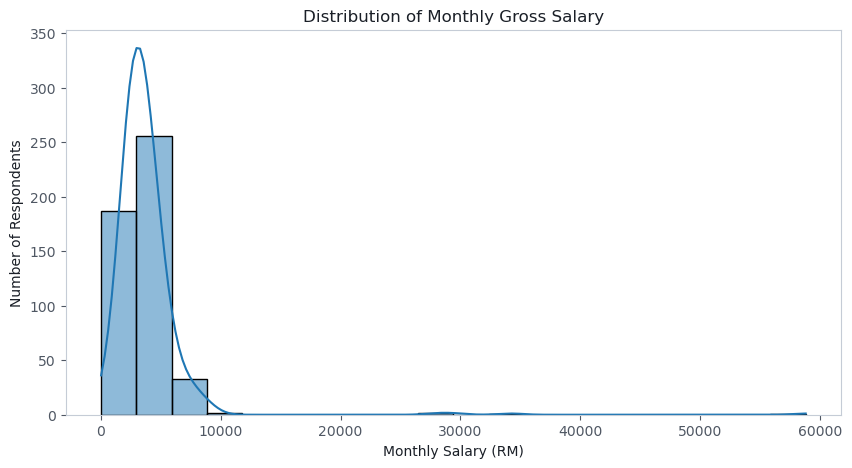

In [157]:
# Salary Distribution Histogram

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["Salary_Analysis"].dropna(),
    bins=20,
    kde=True
)

plt.title("Distribution of Monthly Gross Salary")
plt.xlabel("Monthly Salary (RM)")
plt.ylabel("Number of Respondents")

plt.show()

In [158]:
# STEP 6: DESCRIPTIVE STATISTICS

# Identify important numerical variables

variable_codes = {
    "Age": "A04",
    "Education": "C02",
    "Work Experience": "D01",
    "Working Hours": "D02"
}

# Find the exact column names

selected_columns = {}

for name, code in variable_codes.items():
    matching_columns = [
        col for col in df_clean.columns
        if col.startswith(code)
    ]

    if matching_columns:
        selected_columns[name] = matching_columns[0]

# Create descriptive statistics dataset

descriptive_data = pd.DataFrame()

for name, col in selected_columns.items():
    descriptive_data[name] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

descriptive_data["Monthly Salary"] = df_clean["Salary_Analysis"]

# Calculate descriptive statistics

statistics = descriptive_data.describe().T

print("DESCRIPTIVE STATISTICS")

display(statistics.round(2))

DESCRIPTIVE STATISTICS
                 count     mean      std   min      25%     50%     75%      max
Age              509.0    47.30   150.29 -99.0    29.00    34.0    40.0   1991.0
Education        507.0    13.18     7.78 -99.0    11.00    14.0    16.0     45.0
Work Experience  500.0    14.45    12.18 -99.0     7.75    13.0    20.0     50.0
Working Hours    503.0    43.17    11.39   0.0    40.50    44.0    48.0    200.0
Monthly Salary   482.0  3784.82  3626.67  21.2  2500.00  3300.0  4300.0  58800.0


In [159]:
# STEP 7: CORRELATION ANALYSIS

# Select variables for correlation analysis

correlation_data = descriptive_data.copy()

# Calculate Spearman correlation

correlation_matrix = correlation_data.corr(
    method="spearman"
)

print("SPEARMAN CORRELATION MATRIX")

display(correlation_matrix.round(3))

SPEARMAN CORRELATION MATRIX
                   Age  Education  Work Experience  Working Hours  Monthly Salary
Age              1.000     -0.204            0.902         -0.026           0.210
Education       -0.204      1.000           -0.455         -0.011           0.406
Work Experience  0.902     -0.455            1.000         -0.013           0.089
Working Hours   -0.026     -0.011           -0.013          1.000           0.261
Monthly Salary   0.210      0.406            0.089          0.261           1.000


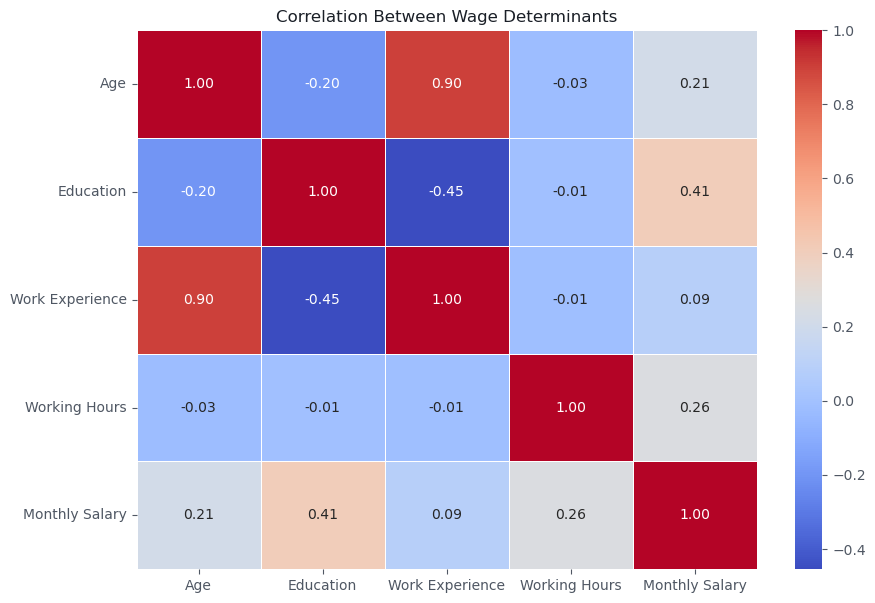

In [160]:
# Create correlation heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Wage Determinants")

plt.show()

### Interpretation of Correlation Analysis

The Spearman correlation analysis shows that education has the strongest positive relationship with monthly salary, with a correlation coefficient of 0.41. This suggests that employees with higher levels of education tend to earn higher salaries.

Working hours (0.26) and age (0.21) also show weak positive relationships with monthly salary. Meanwhile, work experience (0.09) has a very weak positive relationship with wages.

Additionally, age and work experience have a very strong positive correlation of 0.90, suggesting a potential multicollinearity issue in the regression analysis.

In [161]:
# STEP 8: CHECK UNUSUAL DATA VALUES

# Identify respondents with unusual ages

age_column = selected_columns["Age"]

unusual_age = df_clean[
    pd.to_numeric(df_clean[age_column], errors="coerce") > 100
]

print("Respondents with age above 100:")
display(unusual_age[[age_column]])

Respondents with age above 100:
    A04 — What is your age (completed years)?
45                                       1967
127                                      1991
300                                       340
412                                      1990


In [162]:
# Identify respondents with unusual education years

education_column = selected_columns["Education"]

unusual_education = df_clean[
    pd.to_numeric(df_clean[education_column], errors="coerce") > 30
]

print("Respondents with education above 30 years:")
display(unusual_education[[education_column]])

Respondents with education above 30 years:
    C02 — How many years of formal education have you completed in total?
419                                                 45                   


In [163]:
# Investigate unusual age records

print("Original records with unusual ages:")

display(
    df_clean.loc[
        unusual_age.index,
        [
            age_column,
            salary_column,
            selected_columns["Education"],
            selected_columns["Work Experience"]
        ]
    ]
)

Original records with unusual ages:
    A04 — What is your age (completed years)? B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  \
45                                       1967                                               1426                                                           
127                                      1991                                               1900                                                           
300                                       340                                               2400                                                           
412                                      1990                                               4500                                                           

    C02 — How many years of formal education have you completed in total? D01 — Across all paid jobs, how many years of work experience have you accumulated?  
45                     

In [164]:
# Investigate unusual education record

print("Original record with unusual education:")

display(
    df_clean.loc[
        unusual_education.index,
        [
            age_column,
            salary_column,
            selected_columns["Education"],
            selected_columns["Work Experience"]
        ]
    ]
)

Original record with unusual education:
    A04 — What is your age (completed years)? B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  \
419                                        27                                               1700                                                           

    C02 — How many years of formal education have you completed in total? D01 — Across all paid jobs, how many years of work experience have you accumulated?  
419                                                 45                                                                     4                                   


In [165]:
# Display complete unusual age records

columns_to_check = [
    age_column,
    selected_columns["Education"],
    selected_columns["Work Experience"],
    salary_column
]

print("Unusual age records:")

print(
    df_clean.loc[
        unusual_age.index,
        columns_to_check
    ].to_string()
)

Unusual age records:
    A04 — What is your age (completed years)? C02 — How many years of formal education have you completed in total? D01 — Across all paid jobs, how many years of work experience have you accumulated? B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?
45                                       1967                                                                    11                                                                                  41                                                                                                       1426
127                                      1991                                                                     9                                                                                  18                                                                                                       1900
300                                       340             

In [166]:
# Display complete unusual education records

print("Unusual education records:")

print(
    df_clean.loc[
        unusual_education.index,
        columns_to_check
    ].to_string()
)

Unusual education records:
    A04 — What is your age (completed years)? C02 — How many years of formal education have you completed in total? D01 — Across all paid jobs, how many years of work experience have you accumulated? B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?
419                                        27                                                                    45                                                                                   4                                                                                                       1700


In [167]:
# STEP 8.5: Clean unusual age and education values

# Create a separate analysis dataset
df_analysis = df_clean.copy()

# Convert age and education into numerical values
df_analysis[age_column] = pd.to_numeric(
    df_analysis[age_column], errors="coerce"
)

df_analysis[education_column] = pd.to_numeric(
    df_analysis[education_column], errors="coerce"
)

# Treat age above 100 as missing
df_analysis.loc[
    df_analysis[age_column] > 100,
    age_column
] = np.nan

# Treat education above 30 years as missing
df_analysis.loc[
    df_analysis[education_column] > 30,
    education_column
] = np.nan

print("Age and education cleaning completed.")

print("\nMissing age values:")
print(df_analysis[age_column].isnull().sum())

print("\nMissing education values:")
print(df_analysis[education_column].isnull().sum())

Age and education cleaning completed.

Missing age values:
7

Missing education values:
6


In [168]:
# Updated descriptive statistics

updated_data = descriptive_data.copy()

updated_data["Age"] = df_analysis[age_column]
updated_data["Education"] = df_analysis[education_column]
updated_data["Monthly Salary"] = df_analysis["Salary_Analysis"]

print("UPDATED DESCRIPTIVE STATISTICS")

display(updated_data.describe().T.round(2))

UPDATED DESCRIPTIVE STATISTICS
                 count     mean      std   min      25%     50%     75%      max
Age              505.0    35.23    12.37 -99.0    29.00    34.0    40.0     72.0
Education        506.0    13.12     7.66 -99.0    11.00    14.0    16.0     22.0
Work Experience  500.0    14.45    12.18 -99.0     7.75    13.0    20.0     50.0
Working Hours    503.0    43.17    11.39   0.0    40.50    44.0    48.0    200.0
Monthly Salary   482.0  3784.82  3626.67  21.2  2500.00  3300.0  4300.0  58800.0


In [169]:
# Investigate unusual working hours

hours_column = selected_columns["Working Hours"]

unusual_hours = df_analysis[
    pd.to_numeric(
        df_analysis[hours_column],
        errors="coerce"
    ) > 100
]

print("Respondents working more than 100 hours per week:")

display(
    unusual_hours[
        [
            age_column,
            hours_column,
            selected_columns["Work Experience"],
            salary_column
        ]
    ]
)

Respondents working more than 100 hours per week:
     A04 — What is your age (completed years)? D02 — How many hours do you usually work per week in your primary paid job?  \
354                                       49.0                                                110                            
393                                       34.0                                                200                            

    D01 — Across all paid jobs, how many years of work experience have you accumulated? B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  
354                                                 33                                                                                2400                                                          
393                                                 10                                                                                6000                                       

In [170]:
# Investigate high salary observations

high_salary_records = df_analysis[
    df_analysis["Salary_Analysis"] > 20000
]

print("Salary observations above RM20,000:")

display(
    high_salary_records[
        [
            age_column,
            selected_columns["Education"],
            selected_columns["Work Experience"],
            hours_column,
            salary_column,
            "Salary_Analysis"
        ]
    ]
)

Salary observations above RM20,000:
     A04 — What is your age (completed years)?  C02 — How many years of formal education have you completed in total?  \
10                                        39.0                                               17.0                       
74                                        29.0                                               11.0                       
86                                        40.0                                               11.0                       
478                                       40.0                                               17.0                       

    D01 — Across all paid jobs, how many years of work experience have you accumulated? D02 — How many hours do you usually work per week in your primary paid job?  \
10                                                  15                                                                                  47                            
74                      

In [171]:
# Display exact unusual working hours

print("Complete working hours records:")

print(
    unusual_hours[
        [
            age_column,
            hours_column,
            selected_columns["Work Experience"],
            salary_column
        ]
    ].to_string()
)

Complete working hours records:
     A04 — What is your age (completed years)? D02 — How many hours do you usually work per week in your primary paid job? D01 — Across all paid jobs, how many years of work experience have you accumulated? B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?
354                                       49.0                                                                         110                                                                                  33                                                                                                       2400
393                                       34.0                                                                         200                                                                                  10                                                                                                       6000


In [172]:
# STEP 8.9: Clean working hours

# Convert working hours into numerical format

df_analysis["Working_Hours_Analysis"] = pd.to_numeric(
    df_analysis[hours_column],
    errors="coerce"
)

# Treat impossible working hours (above 168) as missing

df_analysis.loc[
    df_analysis["Working_Hours_Analysis"] > 168,
    "Working_Hours_Analysis"
] = np.nan

print("Working hours cleaning completed.")

print("\nMissing working hours:")
print(
    df_analysis["Working_Hours_Analysis"].isnull().sum()
)

print("\nUpdated working hours statistics:")
print(
    df_analysis["Working_Hours_Analysis"].describe()
)

Working hours cleaning completed.

Missing working hours:
10

Updated working hours statistics:
count    502.000000
mean      42.862550
std        8.987407
min        0.000000
25%       40.250000
50%       44.000000
75%       48.000000
max      110.000000
Name: Working_Hours_Analysis, dtype: float64


### Treatment of Unusual Working Hours

The dataset contained two unusual working-hour observations of 110 and 200 hours per week. The value of 200 hours was treated as missing because it exceeds the maximum possible hours in a week (168 hours). The observation of 110 hours was retained temporarily for further verification because it is unusually high but mathematically possible. The original dataset was preserved to maintain data integrity.

In [173]:
# Investigate zero and unusually high working hours

print("Respondents reporting zero working hours:")

display(
    df_analysis[
        df_analysis["Working_Hours_Analysis"] == 0
    ][
        [
            age_column,
            hours_column,
            selected_columns["Work Experience"],
            salary_column
        ]
    ]
)

print("\nRespondents working 60 hours or more:")

display(
    df_analysis[
        df_analysis["Working_Hours_Analysis"] >= 60
    ][
        [
            age_column,
            hours_column,
            selected_columns["Work Experience"],
            salary_column
        ]
    ]
)

Respondents reporting zero working hours:
     A04 — What is your age (completed years)? D02 — How many hours do you usually work per week in your primary paid job?  \
208                                       33.0                                                  0                            

    D01 — Across all paid jobs, how many years of work experience have you accumulated? B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  
208                                                 13                                                                                2300                                                          

Respondents working 60 hours or more:
     A04 — What is your age (completed years)? D02 — How many hours do you usually work per week in your primary paid job?  \
354                                       49.0                                                110                            

    D01 — Across al

In [174]:
# STEP 8.11: Finalise working-hours cleaning

# Treat zero working hours as missing

df_analysis.loc[
    df_analysis["Working_Hours_Analysis"] == 0,
    "Working_Hours_Analysis"
] = np.nan

print("Final working-hours cleaning completed.")

print("\nMissing working hours:")
print(
    df_analysis["Working_Hours_Analysis"].isnull().sum()
)

print("\nUpdated working-hours statistics:")
print(
    df_analysis["Working_Hours_Analysis"].describe()
)

Final working-hours cleaning completed.

Missing working hours:
11

Updated working-hours statistics:
count    501.000000
mean      42.948104
std        8.789386
min        8.000000
25%       41.000000
50%       44.000000
75%       48.000000
max      110.000000
Name: Working_Hours_Analysis, dtype: float64


### Final Treatment of Unusual Working Hours

The dataset contained two unusual working-hour observations. One respondent reported zero working hours despite receiving a monthly salary of RM2,300. Therefore, this value was treated as missing because it may represent an inaccurate response. Another respondent reported 110 working hours per week. This observation was retained temporarily because it is mathematically possible, although it requires further verification. The original dataset was preserved.

In [175]:
# STEP 9.1: Identify variables for regression analysis

# List all required variable codes
variable_codes = [
    "A04",       # Age
    "C02",       # Education
    "D01",       # Work Experience
    "D02",       # Working Hours
    "D03",       # Occupational Group
    "DSP",       # Digital Skills
    "ICS",       # Communication Skills
    "PNB",       # Professional Networking
    "JTC",       # Job Task Complexity
    "D04",       # Industry
    "D05",       # Company Size
    "G04",       # Training Participation
    "G05"        # Training Hours
]

print("REQUIRED VARIABLES AND THEIR COLUMN NAMES")

for code in variable_codes:
    print(f"\n{code}:")
    for col in df_analysis.columns:
        if col.startswith(code):
            print(" -", col)

REQUIRED VARIABLES AND THEIR COLUMN NAMES

A04:
 - A04 — What is your age (completed years)?

C02:
 - C02 — How many years of formal education have you completed in total?

D01:
 - D01 — Across all paid jobs, how many years of work experience have you accumulated?

D02:
 - D02 — How many hours do you usually work per week in your primary paid job?

D03:
 - D03 — Which occupational group best describes your primary job?
 - D03-job-title — Optional job title (do not include the employer’s name):

DSP:
 - DSP1 — I can use digital devices and software effectively to perform my work.
 - DSP2 — I can find, evaluate and organise digital information relevant to my work.
 - DSP3 — I can communicate and collaborate with others using digital technologies.
 - DSP4 — I can solve routine work problems using digital tools.

ICS:
 - ICS1 — I communicate clearly with colleagues and clients.
 - ICS2 — I listen carefully and understand other people’s viewpoints.
 - ICS3 — I cooperate effectively with peo

In [176]:
# STEP 9.2: Examine categorical and training variables

# Identify categorical variables
categorical_variables = {
    "Occupational Group": "D03 -",
    "Industry": "D04 -",
    "Company Size": "D05 -",
    "Training Participation": "G04 -",
    "Training Hours": "G05 -"
}

for name, prefix in categorical_variables.items():

    matching_columns = [
        col for col in df_analysis.columns
        if col.startswith(prefix)
    ]

    print("\n" + "=" * 60)
    print(name.upper())

    for col in matching_columns:
        print("\nColumn:", col)
        print("Unique values:")
        print(df_analysis[col].value_counts(dropna=False).head(20))


OCCUPATIONAL GROUP

INDUSTRY

COMPANY SIZE

TRAINING PARTICIPATION

TRAINING HOURS


In [177]:
# STEP 9.2: Check actual column names

search_codes = ["D03", "D04", "D05", "G04", "G05"]

print("CHECKING ACTUAL COLUMN NAMES")

for code in search_codes:

    print("\n" + "=" * 50)
    print("SEARCHING FOR:", code)

    matching_columns = [
        col for col in df_analysis.columns
        if code in str(col)
    ]

    for col in matching_columns:
        print(repr(col))

CHECKING ACTUAL COLUMN NAMES

SEARCHING FOR: D03
'D03 — Which occupational group best describes your primary job?'
'D03-job-title — Optional job title (do not include the employer’s name):'

SEARCHING FOR: D04
'D04 — What is the main industry of the organisation where you work?'
'D04-other — If you selected “Other services / other” for D04, please specify (optional):'

SEARCHING FOR: D05
'D05 — Approximately how many employees work for your organisation in Malaysia?'

SEARCHING FOR: G04
'G04 — During the past 12 months, have you participated in work-related training or professional-development activities?'
'G05 — IF YES to G04, approximately how many hours of such training did you complete in the past 12 months?'

SEARCHING FOR: G05
'G05 — IF YES to G04, approximately how many hours of such training did you complete in the past 12 months?'
'G05-status — If you did not enter training hours in G05, which applies?'


In [178]:
# STEP 9.3: Examine actual categorical values

# Identify the main columns only
occupational_col = [
    col for col in df_analysis.columns
    if str(col).startswith("D03")
    and "job-title" not in str(col).lower()
][0]

industry_col = [
    col for col in df_analysis.columns
    if str(col).startswith("D04")
    and "other" not in str(col).lower()
][0]

company_col = [
    col for col in df_analysis.columns
    if str(col).startswith("D05")
][0]

training_col = [
    col for col in df_analysis.columns
    if str(col).startswith("G04")
][0]

training_hours_col = [
    col for col in df_analysis.columns
    if str(col).startswith("G05")
    and "status" not in str(col).lower()
][0]

# Display response frequencies
variables_to_examine = {
    "Occupational Group": occupational_col,
    "Industry": industry_col,
    "Company Size": company_col,
    "Training Participation": training_col,
    "Training Hours": training_hours_col
}

for name, col in variables_to_examine.items():

    print("\n" + "=" * 60)
    print(name.upper())
    print("Column:", col)

    print(df_analysis[col].value_counts(dropna=False))


OCCUPATIONAL GROUP
Column: D03 — Which occupational group best describes your primary job?
D03 — Which occupational group best describes your primary job?
Service / sales workers                              98
Professionals                                        93
Technicians / associate professionals                77
Clerical support workers                             71
Managers                                             43
Craft / related trades workers                       26
Plant / machine operators / assemblers               24
Elementary occupations                               24
Professional                                          9
Technician                                            8
Not sure / another category                           7
professionals                                         7
Armed forces occupations                              6
Clerk                                                 4
Manager                                               3
Skil

In [179]:

# STEP 9.4: Clean categorical and training variables

# Create cleaned copies of categorical variables
df_analysis["Occupational_Group_Clean"] = (
    df_analysis[occupational_col].astype("string").str.strip()
)

df_analysis["Industry_Clean"] = (
    df_analysis[industry_col].astype("string").str.strip()
)

df_analysis["Company_Size_Clean"] = (
    df_analysis[company_col].astype("string")
    .str.strip()
    .str.lower()
)

df_analysis["Training_Participation_Clean"] = (
    df_analysis[training_col].astype("string")
    .str.strip()
    .str.lower()
)

# Standardise occupational group responses
occupation_mapping = {
    "professional": "Professionals",
    "professionals": "Professionals",
    "technician": "Technicians / associate professionals",
    "manager": "Managers",
    "clerk": "Clerical support workers",
    "clerical": "Clerical support workers",
    "service worker": "Service / sales workers",
    "sales .": "Service / sales workers",
    "machine operator": "Plant / machine operators / assemblers"
}

df_analysis["Occupational_Group_Clean"] = (
    df_analysis["Occupational_Group_Clean"]
    .str.lower()
    .replace(occupation_mapping)
)

# Standardise company size responses
company_mapping = {
    "200 or more": "200 or more employees",
    "200 or more employees": "200 or more employees",
    "200+": "200 or more employees",
    ">200": "200 or more employees",
    "50-199 employees": "50–199 employees",
    "50 - 199 employees": "50–199 employees",
    "50–199 employees": "50–199 employees",
    "20-49 employees": "20–49 employees",
    "20 - 49 employees": "20–49 employees",
    "20–49 employees": "20–49 employees",
    "1-4 employees": "1–4 employees",
    "1 - 4": "1–4 employees",
    "1–4 employees": "1–4 employees",
    "5-19 employees": "5–19 employees",
    "5 - 19": "5–19 employees",
    "5–19 employees": "5–19 employees",
    "do not know": "Do not know"
}

df_analysis["Company_Size_Clean"] = (
    df_analysis["Company_Size_Clean"]
    .replace(company_mapping)
)

# Standardise training participation
training_mapping = {
    "yes": "Yes",
    "y": "Yes",
    "no": "No",
    "n": "No",
    "do not remember": "Do not remember"
}

df_analysis["Training_Participation_Clean"] = (
    df_analysis["Training_Participation_Clean"]
    .replace(training_mapping)
)

# Convert training hours into numerical format
df_analysis["Training_Hours_Clean"] = pd.to_numeric(
    df_analysis[training_hours_col],
    errors="coerce"
)

# Treat 9999 as an invalid entry
df_analysis.loc[
    df_analysis["Training_Hours_Clean"] == 9999,
    "Training_Hours_Clean"
] = np.nan

print("CATEGORICAL AND TRAINING DATA CLEANING COMPLETED.")

# Display cleaned response frequencies
for col in [
    "Occupational_Group_Clean",
    "Industry_Clean",
    "Company_Size_Clean",
    "Training_Participation_Clean"
]:
    print("\n", col)
    print(df_analysis[col].value_counts(dropna=False))

print("\nTraining hours summary:")
print(df_analysis["Training_Hours_Clean"].describe())

print("\nMissing training hours:")
print(df_analysis["Training_Hours_Clean"].isnull().sum())


CATEGORICAL AND TRAINING DATA CLEANING COMPLETED.

 Occupational_Group_Clean
Occupational_Group_Clean
Professionals                                        109
service / sales workers                               98
technicians / associate professionals                 77
clerical support workers                              71
managers                                              43
craft / related trades workers                        26
plant / machine operators / assemblers                24
elementary occupations                                24
Technicians / associate professionals                  8
not sure / another category                            7
armed forces occupations                               6
Clerical support workers                               6
skilled agricultural / forestry / fishery workers      3
Managers                                               3
Service / sales workers                                3
sales                                      

In [180]:
# STEP 9.5: Final standardisation of categorical variables

# Standardise occupational group
df_analysis["Occupational_Group_Clean"] = (
    df_analysis["Occupational_Group_Clean"]
    .str.strip()
    .str.lower()
)

occupation_mapping = {
    "professionals": "Professionals",
    "service / sales workers": "Service / sales workers",
    "sales": "Service / sales workers",
    "technicians / associate professionals":
        "Technicians / associate professionals",
    "clerical support workers": "Clerical support workers",
    "managers": "Managers",
    "craft / related trades workers":
        "Craft / related trades workers",
    "plant / machine operators / assemblers":
        "Plant / machine operators / assemblers",
    "elementary occupations": "Elementary occupations",
    "not sure / another category":
        "Not sure / another category",
    "armed forces occupations": "Armed forces occupations",
    "skilled agricultural / forestry / fishery workers":
        "Skilled agricultural / forestry / fishery workers"
}

df_analysis["Occupational_Group_Clean"] = (
    df_analysis["Occupational_Group_Clean"]
    .replace(occupation_mapping)
)

# Standardise company size
df_analysis["Company_Size_Clean"] = (
    df_analysis["Company_Size_Clean"]
    .str.strip()
    .str.lower()
)

company_mapping = {
    "200 or more employees": "200 or more employees",
    "50–199 employees": "50–199 employees",
    "50 - 199": "50–199 employees",
    "20–49 employees": "20–49 employees",
    "5–19 employees": "5–19 employees",
    "1–4 employees": "1–4 employees",
    "do not know": "Do not know"
}

df_analysis["Company_Size_Clean"] = (
    df_analysis["Company_Size_Clean"]
    .replace(company_mapping)
)

# Display final cleaned frequencies
print("FINAL OCCUPATIONAL GROUP")
print(df_analysis["Occupational_Group_Clean"].value_counts(dropna=False))

print("\nFINAL COMPANY SIZE")
print(df_analysis["Company_Size_Clean"].value_counts(dropna=False))

print("\nFINAL TRAINING PARTICIPATION")
print(df_analysis["Training_Participation_Clean"].value_counts(dropna=False))

print("\nFINAL TRAINING HOURS")
print(df_analysis["Training_Hours_Clean"].describe())

FINAL OCCUPATIONAL GROUP
Occupational_Group_Clean
Professionals                                        109
Service / sales workers                              104
Technicians / associate professionals                 85
Clerical support workers                              77
Managers                                              46
Craft / related trades workers                        26
Plant / machine operators / assemblers                25
Elementary occupations                                24
Not sure / another category                            7
Armed forces occupations                               6
Skilled agricultural / forestry / fishery workers      3
Name: count, dtype: Int64

FINAL COMPANY SIZE
Company_Size_Clean
200 or more employees    254
50–199 employees          99
20–49 employees           62
5–19 employees            49
1–4 employees             31
Do not know               14
<NA>                       3
Name: count, dtype: Int64

FINAL TRAINING PARTICIPATION

In [181]:

# STEP 9.6: Verify regression variable names

search_codes = [
    "A04", "C02", "D01", "D02", "D03",
    "DSP", "ICS", "PNB", "JTC",
    "D04", "D05", "G04", "G05"
]

print("REGRESSION VARIABLE COLUMN CHECK")

for code in search_codes:
    print("\n" + "=" * 60)
    print("VARIABLE:", code)

    matching_columns = [
        col for col in df_analysis.columns
        if code in str(col)
    ]

    for col in matching_columns:
        print("-", col)


REGRESSION VARIABLE COLUMN CHECK

VARIABLE: A04
- A04 — What is your age (completed years)?

VARIABLE: C02
- C02 — How many years of formal education have you completed in total?

VARIABLE: D01
- D01 — Across all paid jobs, how many years of work experience have you accumulated?

VARIABLE: D02
- D02 — How many hours do you usually work per week in your primary paid job?

VARIABLE: D03
- D03 — Which occupational group best describes your primary job?
- D03-job-title — Optional job title (do not include the employer’s name):

VARIABLE: DSP
- DSP1 — I can use digital devices and software effectively to perform my work.
- DSP2 — I can find, evaluate and organise digital information relevant to my work.
- DSP3 — I can communicate and collaborate with others using digital technologies.
- DSP4 — I can solve routine work problems using digital tools.

VARIABLE: ICS
- ICS1 — I communicate clearly with colleagues and clients.
- ICS2 — I listen carefully and understand other people’s viewpoints.


In [182]:
# STEP 10.1: Examine regression variable values

print("CHECKING NUMERICAL VARIABLES")

numeric_variables = [
    age_column,
    education_column,
    experience_column,
    hours_column,
    salary_column
]

for col in numeric_variables:
    print("\n", col)
    print("Data type:", df_analysis[col].dtype)
    print("Missing values:", df_analysis[col].isnull().sum())
    print("Unique values:", df_analysis[col].nunique())


# Examine Likert-scale variables

print("\nCHECKING LIKERT-SCALE VARIABLES")

likert_prefixes = ["DSP", "ICS", "PNB", "JTC"]

for prefix in likert_prefixes:

    print("\n" + "=" * 50)
    print("VARIABLE GROUP:", prefix)

    matching_columns = [
        col for col in df_analysis.columns
        if str(col).startswith(prefix)
    ]

    for col in matching_columns:

        print("\nColumn:", col)
        print("Data type:", df_analysis[col].dtype)

        print(df_analysis[col].value_counts(
            dropna=False
        ).sort_index())


# Examine training participation and training hours

print("\nCHECKING TRAINING VARIABLES")

print("\nG04 - Training Participation")
print(df_analysis[training_col].value_counts(dropna=False))

print("\nG05 - Training Hours")
print(df_analysis["Training_Hours_Clean"].describe())

CHECKING NUMERICAL VARIABLES

 A04 — What is your age (completed years)?
Data type: float64
Missing values: 7
Unique values: 42

 C02 — How many years of formal education have you completed in total?
Data type: float64
Missing values: 6
Unique values: 16

 D01 — Across all paid jobs, how many years of work experience have you accumulated?
Data type: object
Missing values: 3
Unique values: 69

 D02 — How many hours do you usually work per week in your primary paid job?
Data type: object
Missing values: 4
Unique values: 47

 B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?
Data type: object
Missing values: 22
Unique values: 157

CHECKING LIKERT-SCALE VARIABLES

VARIABLE GROUP: DSP

Column: DSP1 — I can use digital devices and software effectively to perform my work.
Data type: object


Traceback (most recent call last):
  File "<exec>", line 43, in <module>
TypeError: '<' not supported between instances of 'str' and 'int'


In [183]:

# STEP 10.1: Examine regression variable values

# Define work experience column
experience_column = selected_columns["Work Experience"]

print("CHECKING NUMERICAL VARIABLES")

numeric_variables = [
    age_column,
    education_column,
    experience_column,
    hours_column,
    salary_column
]

for col in numeric_variables:
    print("\n", col)
    print("Data type:", df_analysis[col].dtype)
    print("Missing values:", df_analysis[col].isnull().sum())
    print("Unique values:", df_analysis[col].nunique())

# Examine Likert-scale variables

print("\nCHECKING LIKERT-SCALE VARIABLES")

likert_prefixes = ["DSP", "ICS", "PNB", "JTC"]

for prefix in likert_prefixes:

    print("\n" + "=" * 50)
    print("VARIABLE GROUP:", prefix)

    matching_columns = [
        col for col in df_analysis.columns
        if str(col).startswith(prefix)
    ]

    for col in matching_columns:
        print("\nColumn:", col)
        print("Data type:", df_analysis[col].dtype)

        print(df_analysis[col].value_counts(
            dropna=False
        ).sort_index())

# Examine training variables

print("\nCHECKING TRAINING VARIABLES")

print("\nG04 - Training Participation")
print(df_analysis["Training_Participation_Clean"].value_counts(
    dropna=False
))

print("\nG05 - Training Hours")
print(df_analysis["Training_Hours_Clean"].describe())

CHECKING NUMERICAL VARIABLES

 A04 — What is your age (completed years)?
Data type: float64
Missing values: 7
Unique values: 42

 C02 — How many years of formal education have you completed in total?
Data type: float64
Missing values: 6
Unique values: 16

 D01 — Across all paid jobs, how many years of work experience have you accumulated?
Data type: object
Missing values: 3
Unique values: 69

 D02 — How many hours do you usually work per week in your primary paid job?
Data type: object
Missing values: 4
Unique values: 47

 B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?
Data type: object
Missing values: 22
Unique values: 157

CHECKING LIKERT-SCALE VARIABLES

VARIABLE GROUP: DSP

Column: DSP1 — I can use digital devices and software effectively to perform my work.
Data type: object


Traceback (most recent call last):
  File "<exec>", line 45, in <module>
TypeError: '<' not supported between instances of 'str' and 'int'


In [184]:

# STEP 10.1: Examine regression variable values

print("CHECKING NUMERICAL VARIABLES")

numeric_variables = [
    age_column,
    education_column,
    experience_column,
    hours_column,
    salary_column
]

for col in numeric_variables:
    print("\n", col)
    print("Data type:", df_analysis[col].dtype)
    print("Missing values:", df_analysis[col].isnull().sum())
    print("Unique values:", df_analysis[col].nunique())

# Examine Likert-scale variables

print("\nCHECKING LIKERT-SCALE VARIABLES")

likert_prefixes = ["DSP", "ICS", "PNB", "JTC"]

for prefix in likert_prefixes:

    print("\n" + "=" * 50)
    print("VARIABLE GROUP:", prefix)

    matching_columns = [
        col for col in df_analysis.columns
        if str(col).startswith(prefix)
    ]

    for col in matching_columns:
        print("\nColumn:", col)
        print("Data type:", df_analysis[col].dtype)
        print("Missing values:", df_analysis[col].isnull().sum())

        print("Response frequencies:")
        print(df_analysis[col].value_counts(dropna=False))

# Examine training variables

print("\nCHECKING TRAINING VARIABLES")

print("\nG04 - Training Participation")
print(df_analysis["Training_Participation_Clean"].value_counts(
    dropna=False
))

print("\nG05 - Training Hours")
print(df_analysis["Training_Hours_Clean"].describe())

CHECKING NUMERICAL VARIABLES

 A04 — What is your age (completed years)?
Data type: float64
Missing values: 7
Unique values: 42

 C02 — How many years of formal education have you completed in total?
Data type: float64
Missing values: 6
Unique values: 16

 D01 — Across all paid jobs, how many years of work experience have you accumulated?
Data type: object
Missing values: 3
Unique values: 69

 D02 — How many hours do you usually work per week in your primary paid job?
Data type: object
Missing values: 4
Unique values: 47

 B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?
Data type: object
Missing values: 22
Unique values: 157

CHECKING LIKERT-SCALE VARIABLES

VARIABLE GROUP: DSP

Column: DSP1 — I can use digital devices and software effectively to perform my work.
Data type: object
Missing values: 3
Response frequencies:
DSP1 — I can use digital devices and software effectively to perform my work.
3                     179
4    

In [185]:
# STEP 10.2: Convert numerical regression variables

print("CLEANING NUMERICAL REGRESSION VARIABLES")

# Convert work experience
df_analysis["Work_Experience_Clean"] = pd.to_numeric(
    df_analysis[experience_column],
    errors="coerce"
)

# Convert working hours
df_analysis["Working_Hours_Regression"] = pd.to_numeric(
    df_analysis[hours_column],
    errors="coerce"
)

# Convert monthly salary
df_analysis["Monthly_Salary_Regression"] = pd.to_numeric(
    df_analysis[salary_column].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

print("\nNUMERICAL VARIABLE CLEANING COMPLETED")

print("\nMissing values:")

for col in [
    "Work_Experience_Clean",
    "Working_Hours_Regression",
    "Monthly_Salary_Regression"
]:
    print(col, ":", df_analysis[col].isnull().sum())

print("\nUpdated descriptive statistics:")

display(
    df_analysis[
        [
            "Work_Experience_Clean",
            "Working_Hours_Regression",
            "Monthly_Salary_Regression"
        ]
    ].describe().round(2)
)

CLEANING NUMERICAL REGRESSION VARIABLES

NUMERICAL VARIABLE CLEANING COMPLETED

Missing values:
Work_Experience_Clean : 12
Working_Hours_Regression : 9
Monthly_Salary_Regression : 40

Updated descriptive statistics:
       Work_Experience_Clean  Working_Hours_Regression  Monthly_Salary_Regression
count                 500.00                    503.00                     472.00
mean                   14.45                     43.17                    7998.30
std                    12.18                     11.39                   64883.37
min                   -99.00                      0.00                   -2440.00
25%                     7.75                     40.50                    2497.50
50%                    13.00                     44.00                    3300.00
75%                    20.00                     48.00                    4338.00
max                    50.00                    200.00                  999999.00


In [186]:
# STEP 10.3: Standardise Likert-scale responses

print("CLEANING LIKERT-SCALE VARIABLES")

agreement_mapping = {
    "1": 1,
    "1 - strongly disagree": 1,
    "strongly disagree": 1,

    "2": 2,
    "2 - disagree": 2,
    "disagree": 2,

    "3": 3,
    "3 - neither": 3,
    "neither": 3,

    "4": 4,
    "4 - agree": 4,
    "agree": 4,

    "5": 5,
    "5 - strongly agree": 5,
    "strongly agree": 5
}

frequency_mapping = {
    "1": 1,
    "1 - never": 1,
    "never": 1,

    "2": 2,
    "2 - rarely": 2,
    "rarely": 2,

    "3": 3,
    "3 - sometimes": 3,
    "sometimes": 3,

    "4": 4,
    "4 - often": 4,
    "often": 4,

    "5": 5,
    "5 - very often": 5,
    "very often": 5
}

likert_groups = {
    "DSP": agreement_mapping,
    "ICS": agreement_mapping,
    "JTC": agreement_mapping,
    "PNB": frequency_mapping
}

for prefix, mapping in likert_groups.items():

    matching_columns = [
        col for col in df_analysis.columns
        if str(col).startswith(prefix)
        and str(col).split(" — ")[0].endswith(("1", "2", "3", "4"))
    ]

    for col in matching_columns:

        cleaned_values = (
            df_analysis[col]
            .astype("string")
            .str.strip()
            .str.lower()
        )

        df_analysis[col + "_Clean"] = (
            cleaned_values.map(mapping)
            .astype("Int64")
        )

print("Likert-scale cleaning completed.")

CLEANING LIKERT-SCALE VARIABLES
Likert-scale cleaning completed.


In [187]:
# STEP 10.4: Verify cleaned Likert-scale variables

print("FINAL LIKERT-SCALE CLEANING CHECK")

for prefix in ["DSP", "ICS", "PNB", "JTC"]:

    print("\n" + "=" * 50)
    print("VARIABLE GROUP:", prefix)

    cleaned_columns = [
        col for col in df_analysis.columns
        if str(col).startswith(prefix)
        and col.endswith("_Clean")
    ]

    for col in cleaned_columns:

        print("\n", col)

        print("Response frequencies:")
        print(df_analysis[col].value_counts(dropna=False).sort_index())

        print("Missing values:",
              df_analysis[col].isnull().sum())

FINAL LIKERT-SCALE CLEANING CHECK

VARIABLE GROUP: DSP

 DSP1 — I can use digital devices and software effectively to perform my work._Clean
Response frequencies:
DSP1 — I can use digital devices and software effectively to perform my work._Clean
1         5
2        57
3       196
4       193
5        57
<NA>      4
Name: count, dtype: Int64
Missing values: 4

 DSP2 — I can find, evaluate and organise digital information relevant to my work._Clean
Response frequencies:
DSP2 — I can find, evaluate and organise digital information relevant to my work._Clean
1         7
2        70
3       215
4       170
5        45
<NA>      5
Name: count, dtype: Int64
Missing values: 5

 DSP3 — I can communicate and collaborate with others using digital technologies._Clean
Response frequencies:
DSP3 — I can communicate and collaborate with others using digital technologies._Clean
1         8
2        50
3       215
4       167
5        68
<NA>      4
Name: count, dtype: Int64
Missing values: 4

 DSP4 

In [188]:
# STEP 10.5: Investigate unusual numerical values

print("INVESTIGATING UNUSUAL NUMERICAL VALUES")

# Work Experience
print("\n1. WORK EXPERIENCE")

print("Values below zero:")
print(
    df_analysis.loc[
        df_analysis["Work_Experience_Clean"] < 0,
        experience_column
    ].value_counts(dropna=False)
)

# Working Hours
print("\n2. WORKING HOURS")

print("Values below zero:")
print(
    df_analysis.loc[
        df_analysis["Working_Hours_Regression"] < 0,
        hours_column
    ].value_counts(dropna=False)
)

print("Values above 168:")
print(
    df_analysis.loc[
        df_analysis["Working_Hours_Regression"] > 168,
        hours_column
    ].value_counts(dropna=False)
)

# Monthly Salary
print("\n3. MONTHLY SALARY")

print("Values below or equal to zero:")
print(
    df_analysis.loc[
        df_analysis["Monthly_Salary_Regression"] <= 0,
        salary_column
    ].value_counts(dropna=False)
)

print("Highest 15 salary values:")
print(
    df_analysis["Monthly_Salary_Regression"]
    .sort_values(ascending=False)
    .head(15)
)

INVESTIGATING UNUSUAL NUMERICAL VALUES

1. WORK EXPERIENCE
Values below zero:
D01 — Across all paid jobs, how many years of work experience have you accumulated?
-99    2
Name: count, dtype: int64

2. WORKING HOURS
Values below zero:
Series([], Name: count, dtype: int64)
Values above 168:
D02 — How many hours do you usually work per week in your primary paid job?
200    1
Name: count, dtype: int64

3. MONTHLY SALARY
Values below or equal to zero:
B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?
-2440    1
Name: count, dtype: int64
Highest 15 salary values:
281    999999.0
308    999999.0
86      58800.0
478     34200.0
74      29400.0
10      28000.0
245      9000.0
388      9000.0
307      8800.0
506      8600.0
472      8500.0
383      8500.0
142      8100.0
423      8100.0
187      7700.0
Name: Monthly_Salary_Regression, dtype: float64


In [189]:
# STEP 10.7: Clean unusual numerical values

print("CLEANING UNUSUAL NUMERICAL VALUES")

# 1. Clean work experience
df_analysis["Work_Experience_Clean"] = pd.to_numeric(
    df_analysis[experience_column],
    errors="coerce"
)

df_analysis.loc[
    df_analysis["Work_Experience_Clean"] < 0,
    "Work_Experience_Clean"
] = np.nan


# 2. Clean working hours
df_analysis["Working_Hours_Regression"] = pd.to_numeric(
    df_analysis[hours_column],
    errors="coerce"
)

df_analysis.loc[
    (df_analysis["Working_Hours_Regression"] < 0) |
    (df_analysis["Working_Hours_Regression"] > 168),
    "Working_Hours_Regression"
] = np.nan


# 3. Clean monthly salary
df_analysis["Monthly_Salary_Regression"] = pd.to_numeric(
    df_analysis[salary_column],
    errors="coerce"
)

# Treat negative, zero and special code 999999 as missing
# Only apply 999999 if confirmed as an invalid/special code

df_analysis.loc[
    (df_analysis["Monthly_Salary_Regression"] <= 0) |
    (df_analysis["Monthly_Salary_Regression"] == 999999),
    "Monthly_Salary_Regression"
] = np.nan


# Display missing values
print("\nMISSING VALUES AFTER CLEANING:")

clean_variables = [
    "Work_Experience_Clean",
    "Working_Hours_Regression",
    "Monthly_Salary_Regression"
]

for col in clean_variables:
    print(col, ":", df_analysis[col].isnull().sum())


# Updated descriptive statistics
print("\nUPDATED NUMERICAL STATISTICS:")

display(
    df_analysis[clean_variables].describe().round(2)
)

CLEANING UNUSUAL NUMERICAL VALUES

MISSING VALUES AFTER CLEANING:
Work_Experience_Clean : 14
Working_Hours_Regression : 10
Monthly_Salary_Regression : 46

UPDATED NUMERICAL STATISTICS:
       Work_Experience_Clean  Working_Hours_Regression  Monthly_Salary_Regression
count                 498.00                    502.00                     466.00
mean                   14.90                     42.86                    3795.60
std                     9.85                      8.99                    3677.71
min                     0.50                      0.00                      21.20
25%                     8.00                     40.25                    2500.00
50%                    13.00                     44.00                    3300.00
75%                    20.00                     48.00                    4300.00
max                    50.00                    110.00                   58800.00


In [190]:
# STEP 11.1: Construct composite variables

print("CONSTRUCTING COMPOSITE VARIABLES")

# Define Likert-scale variable groups
likert_groups = {
    "DSP": "Digital_Skills",
    "ICS": "Communication_Skills",
    "PNB": "Professional_Networking",
    "JTC": "Job_Task_Complexity"
}

for prefix, composite_name in likert_groups.items():

    # Identify cleaned questionnaire items
    matching_columns = [
        col for col in df_analysis.columns
        if str(col).startswith(prefix)
        and str(col).endswith("_Clean")
    ]

    print(f"\n{composite_name}")
    print("Items found:", len(matching_columns))

    if len(matching_columns) != 4:
        print("WARNING: Expected 4 items. Check column names.")
        continue

    # Calculate average score
    # Require at least 3 valid responses out of 4
    df_analysis[composite_name] = (
        df_analysis[matching_columns].sum(axis=1, min_count=3)
        /
        df_analysis[matching_columns].count(axis=1)
    )

    print("Items:", matching_columns)


print("\nCOMPOSITE VARIABLE CONSTRUCTION COMPLETED.")

CONSTRUCTING COMPOSITE VARIABLES

Digital_Skills
Items found: 4
Items: ['DSP1 — I can use digital devices and software effectively to perform my work._Clean', 'DSP2 — I can find, evaluate and organise digital information relevant to my work._Clean', 'DSP3 — I can communicate and collaborate with others using digital technologies._Clean', 'DSP4 — I can solve routine work problems using digital tools._Clean']

Communication_Skills
Items found: 4
Items: ['ICS1 — I communicate clearly with colleagues and clients._Clean', 'ICS2 — I listen carefully and understand other people’s viewpoints._Clean', 'ICS3 — I cooperate effectively with people who have different roles or perspectives._Clean', 'ICS4 — I can resolve disagreements constructively._Clean']

Professional_Networking
Items found: 4
Items: ['PNB1 — I maintain professional contacts who may be useful for my career._Clean', 'PNB2 — I regularly expand my professional network._Clean', 'PNB3 — I seek information or advice from professional c

In [191]:
# STEP 11.2: Examine composite variable statistics

composite_variables = [
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity"
]

print("COMPOSITE VARIABLE DESCRIPTIVE STATISTICS")

display(
    df_analysis[composite_variables].describe().round(3)
)

print("\nMISSING VALUES IN COMPOSITE VARIABLES")

print(
    df_analysis[composite_variables].isnull().sum()
)

COMPOSITE VARIABLE DESCRIPTIVE STATISTICS
       Digital_Skills  Communication_Skills  Professional_Networking  Job_Task_Complexity
count           512.0                 511.0                    510.0                512.0
mean            3.392                 3.934                    3.211                3.223
std             0.714                  0.48                     0.71                0.721
min              1.25                   2.0                      1.0                  1.0
25%               3.0                  3.75                     2.75                 2.75
50%              3.25                   4.0                     3.25                 3.25
75%              3.75                  4.25                     3.75                 3.75
max               5.0                   5.0                      5.0                  5.0

MISSING VALUES IN COMPOSITE VARIABLES
Digital_Skills             0
Communication_Skills       1
Professional_Networking    2
Job_Task_Complexity   

In [192]:
# STEP 12.4: Create final regression dataset

print("CREATING FINAL REGRESSION DATASET")

# Define regression variables

regression_data = pd.DataFrame({

    # Dependent variable
    "Monthly_Salary": df_analysis["Monthly_Salary_Regression"],

    # Numerical independent variables
    "Age": df_analysis[age_column],
    "Education": df_analysis[education_column],
    "Work_Experience": df_analysis["Work_Experience_Clean"],
    "Working_Hours": df_analysis["Working_Hours_Regression"],

    # Composite independent variables
    "Digital_Skills": df_analysis["Digital_Skills"],
    "Communication_Skills": df_analysis["Communication_Skills"],
    "Professional_Networking": df_analysis["Professional_Networking"],
    "Job_Task_Complexity": df_analysis["Job_Task_Complexity"],

    # Categorical control variables
    "Occupational_Group": df_analysis["Occupational_Group_Clean"],
    "Industry": df_analysis["Industry_Clean"],
    "Company_Size": df_analysis["Company_Size_Clean"],
    "Training_Participation": df_analysis["Training_Participation_Clean"]

})

# Check dataset before removing missing values

print("\nORIGINAL REGRESSION DATASET:")
print("Rows:", len(regression_data))
print("Columns:", len(regression_data.columns))

print("\nMISSING VALUES BEFORE FINAL SELECTION:")

print(regression_data.isnull().sum())

# Remove observations with missing regression variables

df_regression = regression_data.dropna().copy()

# Display final dataset information

print("\nFINAL REGRESSION DATASET")

print("Total observations:", len(df_regression))
print("Total variables:", len(df_regression.columns))

print("\nMISSING VALUES AFTER FINAL SELECTION:")

print(df_regression.isnull().sum())

print("\nFINAL DATASET PREVIEW:")

display(df_regression.head())

print("\nFINAL DESCRIPTIVE STATISTICS:")

display(df_regression.describe().round(3))

CREATING FINAL REGRESSION DATASET

ORIGINAL REGRESSION DATASET:
Rows: 512
Columns: 13

MISSING VALUES BEFORE FINAL SELECTION:
Monthly_Salary             46
Age                         7
Education                   6
Work_Experience            14
Working_Hours              10
Digital_Skills              0
Communication_Skills        1
Professional_Networking     2
Job_Task_Complexity         0
Occupational_Group          0
Industry                    0
Company_Size                3
Training_Participation      0
dtype: int64

FINAL REGRESSION DATASET
Total observations: 423
Total variables: 13

MISSING VALUES AFTER FINAL SELECTION:
Monthly_Salary             0
Age                        0
Education                  0
Work_Experience            0
Working_Hours              0
Digital_Skills             0
Communication_Skills       0
Professional_Networking    0
Job_Task_Complexity        0
Occupational_Group         0
Industry                   0
Company_Size               0
Training_Parti

In [193]:
# STEP 12.5: Clean age variable

print("CLEANING AGE VARIABLE")

# Convert age into numerical format

df_analysis["Age_Regression"] = pd.to_numeric(
    df_analysis[age_column],
    errors="coerce"
)

# Investigate negative age values

print("\nNegative age values:")

print(
    df_analysis.loc[
        df_analysis["Age_Regression"] < 0,
        "Age_Regression"
    ].value_counts()
)

# Treat negative age values as missing

df_analysis.loc[
    df_analysis["Age_Regression"] < 0,
    "Age_Regression"
] = np.nan

print("\nMissing age values after cleaning:")

print(df_analysis["Age_Regression"].isnull().sum())

print("\nUpdated age statistics:")

display(
    df_analysis["Age_Regression"].describe().round(2)
)

CLEANING AGE VARIABLE

Negative age values:
Age_Regression
-99.0    2
Name: count, dtype: int64

Missing age values after cleaning:
9

Updated age statistics:
count    503.00
mean      35.76
std        9.03
min        3.00
25%       29.00
50%       34.00
75%       40.00
max       72.00
Name: Age_Regression, dtype: float64


In [194]:
# STEP 12.6: Recreate final regression dataset

regression_data = pd.DataFrame({

    "Monthly_Salary": df_analysis["Monthly_Salary_Regression"],

    "Age": df_analysis["Age_Regression"],
    "Education": df_analysis[education_column],
    "Work_Experience": df_analysis["Work_Experience_Clean"],
    "Working_Hours": df_analysis["Working_Hours_Regression"],

    "Digital_Skills": df_analysis["Digital_Skills"],
    "Communication_Skills": df_analysis["Communication_Skills"],
    "Professional_Networking": df_analysis["Professional_Networking"],
    "Job_Task_Complexity": df_analysis["Job_Task_Complexity"],

    "Occupational_Group": df_analysis["Occupational_Group_Clean"],
    "Industry": df_analysis["Industry_Clean"],
    "Company_Size": df_analysis["Company_Size_Clean"],
    "Training_Participation": df_analysis["Training_Participation_Clean"]

})

# Remove incomplete observations

df_regression = regression_data.dropna().copy()

print("UPDATED FINAL REGRESSION DATASET")

print("\nTotal observations:", len(df_regression))

print("\nMissing values:")

print(df_regression.isnull().sum())

print("\nUpdated descriptive statistics:")

display(
    df_regression.describe().round(3)
)

UPDATED FINAL REGRESSION DATASET

Total observations: 421

Missing values:
Monthly_Salary             0
Age                        0
Education                  0
Work_Experience            0
Working_Hours              0
Digital_Skills             0
Communication_Skills       0
Professional_Networking    0
Job_Task_Complexity        0
Occupational_Group         0
Industry                   0
Company_Size               0
Training_Participation     0
dtype: int64

Updated descriptive statistics:
       Monthly_Salary      Age  Education  Work_Experience  Working_Hours  Digital_Skills  Communication_Skills  Professional_Networking  Job_Task_Complexity
count         421.000  421.000    421.000          421.000        421.000           421.0                 421.0                    421.0                421.0
mean         3838.142   35.468     13.143           14.500         42.933           3.424                 3.946                    3.231                3.251
std          3831.249    9.0

In [195]:
# STEP 12.7: Investigate unusual age values

print("Respondents with age below 18:")

unusual_age_records = df_analysis[
    df_analysis["Age_Regression"] < 18
]

display(
    unusual_age_records[
        [
            age_column,
            education_column,
            experience_column,
            salary_column
        ]
    ]
)

Respondents with age below 18:
     A04 — What is your age (completed years)?  C02 — How many years of formal education have you completed in total?  \
303                                       17.0                                               18.0                       
492                                        3.0                                               16.0                       

    D01 — Across all paid jobs, how many years of work experience have you accumulated? B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  
303                                                 14                                                                                3590                                                          
492                                                 12                                                                                2100                                                          


In [196]:
# STEP 12.8: Final regression dataset verification

print("FINAL REGRESSION DATASET CHECK")

print("\nNumber of observations:", len(df_regression))

print("\nNumber of variables:", len(df_regression.columns))

print("\nMissing values:")
print(df_regression.isnull().sum())

print("\nDescriptive statistics:")
display(df_regression.describe().round(2))

FINAL REGRESSION DATASET CHECK

Number of observations: 421

Number of variables: 13

Missing values:
Monthly_Salary             0
Age                        0
Education                  0
Work_Experience            0
Working_Hours              0
Digital_Skills             0
Communication_Skills       0
Professional_Networking    0
Job_Task_Complexity        0
Occupational_Group         0
Industry                   0
Company_Size               0
Training_Participation     0
dtype: int64

Descriptive statistics:
       Monthly_Salary     Age  Education  Work_Experience  Working_Hours  Digital_Skills  Communication_Skills  Professional_Networking  Job_Task_Complexity
count          421.00  421.00     421.00           421.00         421.00           421.0                 421.0                    421.0                421.0
mean          3838.14   35.47      13.14            14.50          42.93            3.42                  3.95                     3.23                 3.25
std         

In [197]:
# Treat age 3 as an invalid age value
df_analysis.loc[df_analysis["Age_Regression"] == 3, "Age_Regression"] = np.nan

print("Age value corrected.")
print("Number of missing age values:",
      df_analysis["Age_Regression"].isnull().sum())

Age value corrected.
Number of missing age values: 10


In [198]:
regression_columns = [
    "Monthly_Salary_Regression",
    "Age_Regression",
    "Education",
    "Work_Experience_Clean",
    "Working_Hours_Regression",
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity",
    "Occupational_Group_Clean",
    "Industry_Clean",
    "Company_Size_Clean",
    "Training_Participation_Clean"
]

df_regression = df_analysis[regression_columns].dropna().copy()

print("Updated regression dataset shape:", df_regression.shape)

Traceback (most recent call last):
  File "<exec>", line 17, in <module>
KeyError: "['Education'] not in index"


In [199]:
# Display all available columns in df_analysis
for col in df_analysis.columns:
    print(col)

Timestamp
A04 — What is your age (completed years)?
A05 — How do you describe your gender?
B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?
B01-refusal — If you are not reporting a salary for B01, would you prefer not to disclose it?
B02 — How are you usually paid?
C01 — What is the highest qualification you have completed?
C02 — How many years of formal education have you completed in total?
D01 — Across all paid jobs, how many years of work experience have you accumulated?
D02 — How many hours do you usually work per week in your primary paid job?
D03 — Which occupational group best describes your primary job?
D03-job-title — Optional job title (do not include the employer’s name):
D04 — What is the main industry of the organisation where you work?
D04-other — If you selected “Other services / other” for D04, please specify (optional):
D05 — Approximately how many employees work for your organisation in Malaysia?
DSP1 — I can 

In [200]:
# STEP 12.7.2: Rebuild the regression dataset

regression_columns = [
    "Monthly_Salary_Regression",
    "Age_Regression",
    "C02 — How many years of formal education have you completed in total?",
    "Work_Experience_Clean",
    "Working_Hours_Regression",
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity",
    "Occupational_Group_Clean",
    "Industry_Clean",
    "Company_Size_Clean",
    "Training_Participation_Clean"
]

df_regression = df_analysis[regression_columns].dropna().copy()

print("Updated regression dataset shape:", df_regression.shape)
print("\nNumber of observations:", len(df_regression))
print("\nNumber of variables:", len(df_regression.columns))

Updated regression dataset shape: (420, 13)

Number of observations: 420

Number of variables: 13


In [201]:
# STEP 12.8: Final regression dataset verification

print("FINAL REGRESSION DATASET CHECK")

print("\nNumber of observations:", len(df_regression))
print("\nNumber of variables:", len(df_regression.columns))

print("\nMissing values:")
print(df_regression.isnull().sum())

print("\nDescriptive statistics:")
display(df_regression.describe().round(2))

FINAL REGRESSION DATASET CHECK

Number of observations: 420

Number of variables: 13

Missing values:
Monthly_Salary_Regression                                                0
Age_Regression                                                           0
C02 — How many years of formal education have you completed in total?    0
Work_Experience_Clean                                                    0
Working_Hours_Regression                                                 0
Digital_Skills                                                           0
Communication_Skills                                                     0
Professional_Networking                                                  0
Job_Task_Complexity                                                      0
Occupational_Group_Clean                                                 0
Industry_Clean                                                           0
Company_Size_Clean                                                       

In [202]:
# STEP 13: Detailed descriptive statistics

numerical_columns = [
    "Monthly_Salary_Regression",
    "Age_Regression",
    "C02 — How many years of formal education have you completed in total?",
    "Work_Experience_Clean",
    "Working_Hours_Regression",
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity"
]

descriptive_stats = df_regression[numerical_columns].describe().T

display(descriptive_stats.round(2))

                                                    count         mean          std   min     25%     50%     75%      max
Monthly_Salary_Regression                           420.0  3842.280238  3834.876314  21.2  2500.0  3325.0  4308.5  58800.0
Age_Regression                                      420.0    35.545238     8.938685  17.0    29.0    34.0    40.0     72.0
C02 — How many years of formal education have y...  420.0    13.135714     8.327036 -99.0    11.0    14.0    16.0     22.0
Work_Experience_Clean                               420.0    14.505952     9.843917   0.5     7.0    13.0    19.0     50.0
Working_Hours_Regression                            420.0    42.935714     9.122772   0.0    41.0    45.0    48.0    110.0
Digital_Skills                                      420.0     3.425595     0.729422  1.25     3.0     3.5     4.0      5.0
Communication_Skills                                420.0      3.94623     0.475503   2.0    3.75     4.0    4.25      5.0
Professional_Net

In [203]:
# STEP 14: Frequency distribution of categorical variables

categorical_columns = [
    "Occupational_Group_Clean",
    "Industry_Clean",
    "Company_Size_Clean",
    "Training_Participation_Clean"
]

for col in categorical_columns:
    print("\n", "=" * 60)
    print(col)
    print("=" * 60)

    display(
        df_regression[col]
        .value_counts()
        .to_frame("Frequency")
    )


Occupational_Group_Clean
                                                   Frequency
Occupational_Group_Clean                                    
Professionals                                             91
Service / sales workers                                   82
Technicians / associate professionals                     75
Clerical support workers                                  59
Managers                                                  37
Craft / related trades workers                            23
Elementary occupations                                    23
Plant / machine operators / assemblers                    18
Not sure / another category                                5
Armed forces occupations                                   5
Skilled agricultural / forestry / fishery workers          2

Industry_Clean
                                                Frequency
Industry_Clean                                           
Manufacturing                                    

In [204]:
# STEP 15: Spearman correlation analysis

correlation_matrix = df_regression[numerical_columns].corr(
    method="spearman"
)

print("SPEARMAN CORRELATION MATRIX")
display(correlation_matrix.round(3))

# Correlation of each variable with monthly salary
salary_correlation = correlation_matrix[
    "Monthly_Salary_Regression"
].sort_values(ascending=False)

print("\nCORRELATION WITH MONTHLY SALARY")
display(salary_correlation.round(3))

SPEARMAN CORRELATION MATRIX
                                                    Monthly_Salary_Regression  Age_Regression  C02 — How many years of formal education have you completed in total?  Work_Experience_Clean  \
Monthly_Salary_Regression                                               1.000           0.225                                              0.417                                      0.097   
Age_Regression                                                          0.225           1.000                                             -0.179                                      0.925   
C02 — How many years of formal education have y...                      0.417          -0.179                                              1.000                                     -0.445   
Work_Experience_Clean                                                   0.097           0.925                                             -0.445                                      1.000   
Working_Hours_Reg

In [205]:
# STEP 16: Correlation among independent variables

predictor_columns = [
    "Age_Regression",
    "C02 — How many years of formal education have you completed in total?",
    "Work_Experience_Clean",
    "Working_Hours_Regression",
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity"
]

# Calculate Spearman correlations
predictor_correlation = df_regression[predictor_columns].corr(
    method="spearman"
)

# Display the full matrix
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("CORRELATION MATRIX AMONG INDEPENDENT VARIABLES")
display(predictor_correlation.round(3))

CORRELATION MATRIX AMONG INDEPENDENT VARIABLES
                                                    Age_Regression  C02 — How many years of formal education have you completed in total?  Work_Experience_Clean  Working_Hours_Regression  \
Age_Regression                                               1.000                                             -0.179                                      0.925                    -0.031   
C02 — How many years of formal education have y...          -0.179                                              1.000                                     -0.445                    -0.008   
Work_Experience_Clean                                        0.925                                             -0.445                                      1.000                    -0.016   
Working_Hours_Regression                                    -0.031                                             -0.008                                     -0.016                     1.000   
Dig

In [206]:
# STEP 17: Variance Inflation Factor (VIF)

from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# Select numerical independent variables
X_vif = df_regression[predictor_columns].copy()

# Calculate VIF for each variable
vif_data = pd.DataFrame()

vif_data["Variable"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Display results
vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

print("VARIANCE INFLATION FACTOR (VIF) RESULTS")
display(vif_data.round(3))

Traceback (most recent call last):
  File "<exec>", line 14, in <module>
TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''


In [207]:
# STEP 17.1: Check predictor data types

print("DATA TYPES OF INDEPENDENT VARIABLES")
print(X_vif.dtypes)

print("\nCHECK FOR NON-NUMERIC VALUES")
for col in X_vif.columns:
    print(f"{col}:")
    print(X_vif[col].map(type).value_counts())

DATA TYPES OF INDEPENDENT VARIABLES
Age_Regression                                                           float64
C02 — How many years of formal education have you completed in total?    float64
Work_Experience_Clean                                                    float64
Working_Hours_Regression                                                 float64
Digital_Skills                                                           Float64
Communication_Skills                                                     Float64
Professional_Networking                                                  Float64
Job_Task_Complexity                                                      Float64
dtype: object

CHECK FOR NON-NUMERIC VALUES
Age_Regression:
Age_Regression
<class 'float'>    420
Name: count, dtype: int64
C02 — How many years of formal education have you completed in total?:
C02 — How many years of formal education have you completed in total?
<class 'float'>    420
Name: count, dtype: int64
Wo

In [208]:
# STEP 17.2: Convert predictors to numeric

X_vif = df_regression[predictor_columns].copy()

for col in X_vif.columns:
    X_vif[col] = pd.to_numeric(X_vif[col], errors="coerce")

print("Data types after conversion:")
print(X_vif.dtypes)

print("\nMissing values after conversion:")
print(X_vif.isnull().sum())

Data types after conversion:
Age_Regression                                                           float64
C02 — How many years of formal education have you completed in total?    float64
Work_Experience_Clean                                                    float64
Working_Hours_Regression                                                 float64
Digital_Skills                                                           Float64
Communication_Skills                                                     Float64
Professional_Networking                                                  Float64
Job_Task_Complexity                                                      Float64
dtype: object

Missing values after conversion:
Age_Regression                                                           0
C02 — How many years of formal education have you completed in total?    0
Work_Experience_Clean                                                    0
Working_Hours_Regression                          

In [209]:
# STEP 17.3: Corrected VIF calculation

import numpy as np
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Convert predictors into a numerical array
X_vif = df_regression[predictor_columns].astype(float)

# Add a constant (intercept)
X_vif_constant = add_constant(X_vif, has_constant="add")

# Convert to NumPy array
X_vif_array = X_vif_constant.to_numpy(dtype=float)

# Calculate VIF
vif_data = pd.DataFrame()

vif_data["Variable"] = X_vif_constant.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif_array, i)
    for i in range(X_vif_array.shape[1])
]

# Exclude the constant from the displayed results
vif_data = vif_data[vif_data["Variable"] != "const"]

# Sort from highest to lowest
vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

print("VARIANCE INFLATION FACTOR (VIF) RESULTS")
display(vif_data.round(3))

VARIANCE INFLATION FACTOR (VIF) RESULTS
                                            Variable     VIF
3                              Work_Experience_Clean  10.959
1                                     Age_Regression  10.441
5                                     Digital_Skills   1.251
8                                Job_Task_Complexity   1.177
2  C02 — How many years of formal education have ...   1.097
6                               Communication_Skills   1.033
7                            Professional_Networking   1.032
4                           Working_Hours_Regression   1.008


In [210]:
# STEP 18: Prepare alternative regression models

# Model 1: Exclude work experience
model1_predictors = [
    "Age_Regression",
    "C02 — How many years of formal education have you completed in total?",
    "Working_Hours_Regression",
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity"
]

# Model 2: Exclude age
model2_predictors = [
    "C02 — How many years of formal education have you completed in total?",
    "Work_Experience_Clean",
    "Working_Hours_Regression",
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity"
]

print("MODEL 1 predictors:")
print(model1_predictors)

print("\nMODEL 2 predictors:")
print(model2_predictors)

MODEL 1 predictors:
['Age_Regression', 'C02 — How many years of formal education have you completed in total?', 'Working_Hours_Regression', 'Digital_Skills', 'Communication_Skills', 'Professional_Networking', 'Job_Task_Complexity']

MODEL 2 predictors:
['C02 — How many years of formal education have you completed in total?', 'Work_Experience_Clean', 'Working_Hours_Regression', 'Digital_Skills', 'Communication_Skills', 'Professional_Networking', 'Job_Task_Complexity']


In [211]:
# STEP 19: Prepare regression dataset

import statsmodels.formula.api as smf

# Create a dataset with shorter, clearer column names
df_model = df_regression.rename(columns={
    "Monthly_Salary_Regression": "Salary",
    "Age_Regression": "Age",
    "C02 — How many years of formal education have you completed in total?": "Education",
    "Work_Experience_Clean": "Experience",
    "Working_Hours_Regression": "Working_Hours",
    "Digital_Skills": "Digital_Skills",
    "Communication_Skills": "Communication_Skills",
    "Professional_Networking": "Professional_Networking",
    "Job_Task_Complexity": "Job_Task_Complexity",
    "Occupational_Group_Clean": "Occupation",
    "Industry_Clean": "Industry",
    "Company_Size_Clean": "Company_Size",
    "Training_Participation_Clean": "Training"
})

print("Regression dataset shape:", df_model.shape)

print("\nCategorical variables:")
for col in ["Occupation", "Industry", "Company_Size", "Training"]:
    print(f"\n{col}:")
    print(df_model[col].value_counts())

Regression dataset shape: (420, 13)

Categorical variables:

Occupation:
Occupation
Professionals                                        91
Service / sales workers                              82
Technicians / associate professionals                75
Clerical support workers                             59
Managers                                             37
Craft / related trades workers                       23
Elementary occupations                               23
Plant / machine operators / assemblers               18
Not sure / another category                           5
Armed forces occupations                              5
Skilled agricultural / forestry / fishery workers     2
Name: count, dtype: Int64

Industry:
Industry
Manufacturing                                     71
Wholesale and retail trade                        38
Finance and insurance                             37
Education                                         33
Professional / scientific / technical serv

In [212]:
# STEP 20: Estimate Multiple Regression Models

import statsmodels.formula.api as smf

# Model 1: Age included, Work Experience excluded
formula1 = """
Salary ~ Age + Education + Working_Hours
+ Digital_Skills + Communication_Skills
+ Professional_Networking + Job_Task_Complexity
+ C(Occupation) + C(Industry)
+ C(Company_Size) + C(Training)
"""

# Model 2: Work Experience included, Age excluded
formula2 = """
Salary ~ Education + Experience + Working_Hours
+ Digital_Skills + Communication_Skills
+ Professional_Networking + Job_Task_Complexity
+ C(Occupation) + C(Industry)
+ C(Company_Size) + C(Training)
"""

# Estimate both models
model1 = smf.ols(formula=formula1, data=df_model).fit(cov_type="HC3")

model2 = smf.ols(formula=formula2, data=df_model).fit(cov_type="HC3")

# Display Model 1
print("=" * 70)
print("MODEL 1: AGE INCLUDED, WORK EXPERIENCE EXCLUDED")
print("=" * 70)
print(model1.summary())

# Display Model 2
print("\n" + "=" * 70)
print("MODEL 2: WORK EXPERIENCE INCLUDED, AGE EXCLUDED")
print("=" * 70)
print(model2.summary())

Traceback (most recent call last):
  File "<exec>", line 24, in <module>
TypeError: Cannot interpret 'string[python]' as a data type


In [213]:
# STEP 20.1: Fix data types for regression

# Create a separate copy
df_model_fixed = df_model.copy()

# Convert categorical variables to object
categorical_vars = [
    "Occupation",
    "Industry",
    "Company_Size",
    "Training"
]

for col in categorical_vars:
    df_model_fixed[col] = df_model_fixed[col].astype(object)

# Convert numerical variables to float
numerical_vars = [
    "Salary",
    "Age",
    "Education",
    "Experience",
    "Working_Hours",
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity"
]

for col in numerical_vars:
    df_model_fixed[col] = pd.to_numeric(
        df_model_fixed[col],
        errors="raise"
    ).astype(float)

print("UPDATED DATA TYPES:")
print(df_model_fixed.dtypes)

print("\nDataset shape:", df_model_fixed.shape)

UPDATED DATA TYPES:
Salary                     float64
Age                        float64
Education                  float64
Experience                 float64
Working_Hours              float64
Digital_Skills             float64
Communication_Skills       float64
Professional_Networking    float64
Job_Task_Complexity        float64
Occupation                  object
Industry                    object
Company_Size                object
Training                    object
dtype: object

Dataset shape: (420, 13)


In [214]:
# STEP 20.2: Estimate both regression models

import statsmodels.formula.api as smf

formula1 = """
Salary ~ Age + Education + Working_Hours
+ Digital_Skills + Communication_Skills
+ Professional_Networking + Job_Task_Complexity
+ C(Occupation) + C(Industry)
+ C(Company_Size) + C(Training)
"""

formula2 = """
Salary ~ Education + Experience + Working_Hours
+ Digital_Skills + Communication_Skills
+ Professional_Networking + Job_Task_Complexity
+ C(Occupation) + C(Industry)
+ C(Company_Size) + C(Training)
"""

# Model 1
model1 = smf.ols(
    formula=formula1,
    data=df_model_fixed
).fit(cov_type="HC3")

# Model 2
model2 = smf.ols(
    formula=formula2,
    data=df_model_fixed
).fit(cov_type="HC3")

print("=" * 60)
print("MODEL 1: AGE INCLUDED")
print("=" * 60)
print(model1.summary())

print("\n" + "=" * 60)
print("MODEL 2: WORK EXPERIENCE INCLUDED")
print("=" * 60)
print(model2.summary())

MODEL 1: AGE INCLUDED
                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.160
Model:                            OLS   Adj. R-squared:                  0.069
Method:                 Least Squares   F-statistic:                     3.965
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           4.77e-13
Time:                        05:42:30   Log-Likelihood:                -4024.6
No. Observations:                 420   AIC:                             8133.
Df Residuals:                     378   BIC:                             8303.
Df Model:                          41                                         
Covariance Type:                  HC3                                         
                                                                         coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------

In [215]:
# STEP 21: Create log-transformed monthly salary

import numpy as np

# Check that all salaries are positive
print("Minimum salary:", df_model_fixed["Salary"].min())

# Create natural logarithm of salary
df_model_fixed["Log_Salary"] = np.log(
    df_model_fixed["Salary"]
)

# Display descriptive statistics
print("\nLOG SALARY DESCRIPTIVE STATISTICS")

display(
    df_model_fixed["Log_Salary"].describe().round(3)
)

Minimum salary: 21.2

LOG SALARY DESCRIPTIVE STATISTICS
count    420.000
mean       8.068
std        0.658
min        3.054
25%        7.824
50%        8.109
75%        8.368
max       10.982
Name: Log_Salary, dtype: float64


In [216]:
# STEP 22: Log-Salary Regression Models

import statsmodels.formula.api as smf

# Model 1: Age included, Experience excluded
log_formula1 = """
Log_Salary ~ Age + Education + Working_Hours
+ Digital_Skills + Communication_Skills
+ Professional_Networking + Job_Task_Complexity
+ C(Occupation) + C(Industry)
+ C(Company_Size) + C(Training)
"""

# Model 2: Experience included, Age excluded
log_formula2 = """
Log_Salary ~ Education + Experience + Working_Hours
+ Digital_Skills + Communication_Skills
+ Professional_Networking + Job_Task_Complexity
+ C(Occupation) + C(Industry)
+ C(Company_Size) + C(Training)
"""

# Estimate Model 1
log_model1 = smf.ols(
    formula=log_formula1,
    data=df_model_fixed
).fit(cov_type="HC3")

# Estimate Model 2
log_model2 = smf.ols(
    formula=log_formula2,
    data=df_model_fixed
).fit(cov_type="HC3")

# Display Model 1
print("=" * 65)
print("LOG MODEL 1: AGE INCLUDED")
print("=" * 65)
print(log_model1.summary())

# Display Model 2
print("\n" + "=" * 65)
print("LOG MODEL 2: EXPERIENCE INCLUDED")
print("=" * 65)
print(log_model2.summary())

LOG MODEL 1: AGE INCLUDED
                            OLS Regression Results                            
Dep. Variable:             Log_Salary   R-squared:                       0.243
Model:                            OLS   Adj. R-squared:                  0.161
Method:                 Least Squares   F-statistic:                     6.693
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           1.09e-25
Time:                        05:42:30   Log-Likelihood:                -361.41
No. Observations:                 420   AIC:                             806.8
Df Residuals:                     378   BIC:                             976.5
Df Model:                          41                                         
Covariance Type:                  HC3                                         
                                                                         coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------

In [217]:
# STEP 23: Compare numerical predictors in both log models

variables = [
    "Age",
    "Education",
    "Experience",
    "Working_Hours",
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity"
]

comparison = pd.DataFrame({
    "Model 1 Coefficient": model1.params.reindex(variables),
    "Model 1 P-value": model1.pvalues.reindex(variables),
    "Model 2 Coefficient": model2.params.reindex(variables),
    "Model 2 P-value": model2.pvalues.reindex(variables)
})

display(comparison.round(4))

                         Model 1 Coefficient  Model 1 P-value  Model 2 Coefficient  Model 2 P-value
Age                                  29.4519           0.0959                  NaN              NaN
Education                            26.7038           0.1879              28.4655           0.1870
Experience                               NaN              NaN              25.2836           0.0933
Working_Hours                        82.5085           0.0024              81.7155           0.0025
Digital_Skills                     -315.0323           0.6192            -321.1507           0.6026
Communication_Skills                283.4482           0.3925             303.9628           0.3536
Professional_Networking              83.9184           0.7327              85.4081           0.7292
Job_Task_Complexity                 879.7813           0.0279             901.3848           0.0214


In [218]:
# STEP 23.1: Correct comparison of LOG regression models

variables = [
    "Age",
    "Education",
    "Experience",
    "Working_Hours",
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity"
]

log_comparison = pd.DataFrame({
    "Model 1 Coefficient": log_model1.params.reindex(variables),
    "Model 1 P-value": log_model1.pvalues.reindex(variables),
    "Model 2 Coefficient": log_model2.params.reindex(variables),
    "Model 2 P-value": log_model2.pvalues.reindex(variables)
})

print("COMPARISON OF LOG-SALARY REGRESSION MODELS")
display(log_comparison.round(4))

COMPARISON OF LOG-SALARY REGRESSION MODELS
                         Model 1 Coefficient  Model 1 P-value  Model 2 Coefficient  Model 2 P-value
Age                                   0.0077           0.0802                  NaN              NaN
Education                             0.0047           0.2778               0.0051           0.2740
Experience                               NaN              NaN               0.0068           0.0900
Working_Hours                         0.0204           0.0001               0.0202           0.0001
Digital_Skills                        0.0359           0.5548               0.0349           0.5573
Communication_Skills                 -0.0201           0.8265              -0.0148           0.8724
Professional_Networking               0.0659           0.1369               0.0662           0.1358
Job_Task_Complexity                   0.1813           0.0002               0.1868           0.0001


In [219]:
# STEP 24: Breusch-Pagan test for heteroskedasticity

from statsmodels.stats.diagnostic import het_breuschpagan

# Use residuals and explanatory variables from log Model 1
bp_test = het_breuschpagan(
    log_model1.resid,
    log_model1.model.exog
)

bp_labels = [
    "LM Statistic",
    "LM P-value",
    "F Statistic",
    "F P-value"
]

print("BREUSCH-PAGAN TEST RESULTS")

for label, value in zip(bp_labels, bp_test):
    print(f"{label}: {value:.4f}")

BREUSCH-PAGAN TEST RESULTS
LM Statistic: 45.8565
LM P-value: 0.2778
F Statistic: 1.1300
F P-value: 0.2758


JARQUE-BERA NORMALITY TEST
JB Statistic: 8683.8233
P-value: 0.0


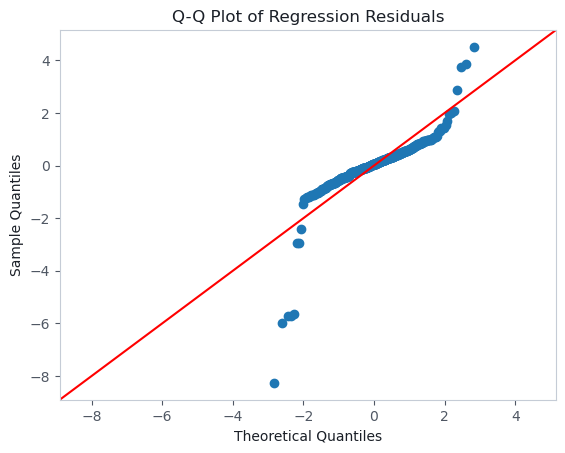

In [220]:
# STEP 25: Residual normality test

from scipy.stats import jarque_bera
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Obtain residuals from Log Model 1
residuals = log_model1.resid

# Jarque-Bera test
jb_stat, jb_pvalue = jarque_bera(residuals)

print("JARQUE-BERA NORMALITY TEST")
print("JB Statistic:", round(jb_stat, 4))
print("P-value:", round(jb_pvalue, 4))

# Plot residual distribution
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30, edgecolor="black")
plt.title("Distribution of Regression Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

# Q-Q plot
sm.qqplot(residuals, line="45", fit=True)
plt.title("Q-Q Plot of Regression Residuals")
plt.show()

In [221]:
# STEP 24: Breusch-Pagan test

from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    log_model1.resid,
    log_model1.model.exog
)

print("BREUSCH-PAGAN TEST")
print("LM Statistic:", round(bp_test[0], 4))
print("LM P-value:", round(bp_test[1], 4))
print("F Statistic:", round(bp_test[2], 4))
print("F P-value:", round(bp_test[3], 4))

BREUSCH-PAGAN TEST
LM Statistic: 45.8565
LM P-value: 0.2778
F Statistic: 1.13
F P-value: 0.2758


JARQUE-BERA NORMALITY TEST
JB Statistic: 8683.8233
P-value: 0.0


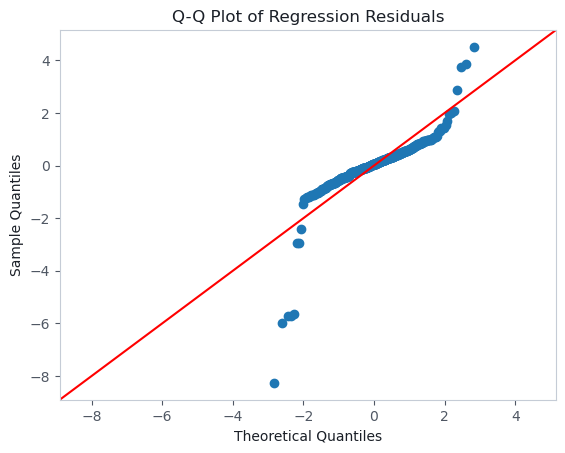

In [222]:
# STEP 25: Jarque-Bera normality test

from scipy.stats import jarque_bera
import matplotlib.pyplot as plt
import statsmodels.api as sm

residuals = log_model1.resid

# Jarque-Bera test
jb_stat, jb_pvalue = jarque_bera(residuals)

print("JARQUE-BERA NORMALITY TEST")
print("JB Statistic:", round(jb_stat, 4))
print("P-value:", round(jb_pvalue, 4))

# Residual histogram
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30, edgecolor="black")
plt.title("Distribution of Regression Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

# Q-Q plot
sm.qqplot(residuals, line="45", fit=True)
plt.title("Q-Q Plot of Regression Residuals")
plt.show()

COOK'S DISTANCE ANALYSIS
Screening threshold: 0.0095

Number of potentially influential observations:
21

Top 10 observations by Cook's Distance:
     Observation  Cooks_Distance
12            12          0.3054
198          198          0.1315
113          113          0.0967
148          148          0.0917
142          142          0.0778
74            74          0.0665
284          284          0.0449
64            64          0.0332
167          167          0.0318
418          418          0.0280


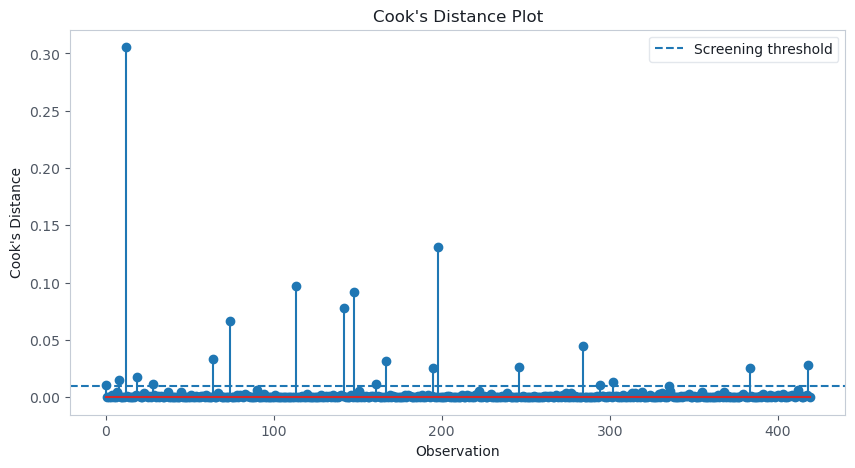

In [223]:
# STEP 26: Check influential observations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Obtain influence statistics
influence = log_model1.get_influence()

# Calculate Cook's Distance
cooks_distance = influence.cooks_distance[0]

# Create a diagnostic dataframe
influence_data = pd.DataFrame({
    "Observation": np.arange(len(cooks_distance)),
    "Cooks_Distance": cooks_distance
})

# Common screening threshold
threshold = 4 / len(df_model_fixed)

print("COOK'S DISTANCE ANALYSIS")
print("Screening threshold:", round(threshold, 4))

# Identify potentially influential observations
influential = influence_data[
    influence_data["Cooks_Distance"] > threshold
]

print("\nNumber of potentially influential observations:")
print(len(influential))

print("\nTop 10 observations by Cook's Distance:")
display(
    influence_data.sort_values(
        by="Cooks_Distance",
        ascending=False
    ).head(10).round(4)
)

# Plot Cook's Distance
plt.figure(figsize=(10, 5))
plt.stem(influence_data["Observation"], cooks_distance)
plt.axhline(
    threshold,
    linestyle="--",
    label="Screening threshold"
)
plt.title("Cook's Distance Plot")
plt.xlabel("Observation")
plt.ylabel("Cook's Distance")
plt.legend()
plt.show()

In [224]:
# STEP 26.1: Inspect potentially influential observations

top_10_indices = (
    influence_data
    .sort_values(
        by="Cooks_Distance",
        ascending=False
    )
    .head(10)["Observation"]
    .astype(int)
    .tolist()
)

# Display the original data for these observations
columns_to_check = [
    "Salary",
    "Age",
    "Education",
    "Experience",
    "Working_Hours",
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity"
]

print("TOP 10 POTENTIALLY INFLUENTIAL OBSERVATIONS")

display(
    df_model_fixed.iloc[top_10_indices][columns_to_check].round(2)
)

TOP 10 POTENTIALLY INFLUENTIAL OBSERVATIONS
      Salary   Age  Education  Experience  Working_Hours  Digital_Skills  Communication_Skills  Professional_Networking  Job_Task_Complexity
14      27.5  28.0       18.0         1.0           26.0            5.00                  4.25                     2.25                 3.00
247     21.2  26.0       16.0         1.0           24.0            3.25                  4.25                     3.75                 3.25
133     67.0  34.0       11.0        15.0           46.0            3.25                  4.75                     2.00                 2.25
183    108.0  34.0       11.0        16.0           39.0            3.50                  2.50                     2.50                 3.00
173    127.0  59.0       12.0        40.0           46.0            3.75                  4.25                     3.50                 3.00
86   58800.0  40.0       11.0        22.0           53.0            1.25                  4.00                

In [225]:
# STEP 26.2: Check original responses of influential observations

# Get the original dataframe index labels
original_indices = df_model_fixed.iloc[top_10_indices].index

# Identify the payment frequency column
payment_column = [
    col for col in df_analysis.columns
    if col.startswith("B02")
][0]

# Select relevant original information
columns_to_check = [
    salary_column,
    payment_column,
    age_column,
    education_column,
    experience_column,
    hours_column
]

print("ORIGINAL QUESTIONNAIRE RESPONSES")
display(
    df_analysis.loc[original_indices, columns_to_check]
)

ORIGINAL QUESTIONNAIRE RESPONSES
    B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month? B02 — How are you usually paid?  A04 — What is your age (completed years)?  \
14                                                27.5                                                                                  Hourly                                       28.0   
247                                               21.2                                                                                  Hourly                                       26.0   
133                                                 67                                                                                   Daily                                       34.0   
183                                                108                                                                                   Daily                                       34.0   
173                   

In [226]:
# STEP 26.3: Examine salary by payment frequency

payment_salary_summary = df_analysis.groupby(
    payment_column
)[salary_column].agg(
    ["count", "mean", "median", "min", "max"]
)

print("SALARY SUMMARY BY PAYMENT FREQUENCY")

display(payment_salary_summary.round(2))

Traceback (most recent call last):
  File "/lib/python3.13/site-packages/pandas/core/groupby/groupby.py", line 1944, in _agg_py_fallback
    res_values = self._grouper.agg_series(ser, alt, preserve_dtype=True)
  File "/lib/python3.13/site-packages/pandas/core/groupby/ops.py", line 873, in agg_series
    result = self._aggregate_series_pure_python(obj, func)
  File "/lib/python3.13/site-packages/pandas/core/groupby/ops.py", line 894, in _aggregate_series_pure_python
    res = func(group)
  File "/lib/python3.13/site-packages/pandas/core/groupby/groupby.py", line 2461, in <lambda>
    alt=lambda x: Series(x, copy=False).mean(numeric_only=numeric_only),
                  ~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/lib/python3.13/site-packages/pandas/core/series.py", line 6570, in mean
    return NDFrame.mean(self, axis, skipna, numeric_only, **kwargs)
           ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/lib/python3.13/site-packages/pandas/core/ge

In [227]:
# STEP 26.3.1: Convert salary into numeric format

salary_numeric = pd.to_numeric(
    df_analysis[salary_column],
    errors="coerce"
)

print("Salary data type:", salary_numeric.dtype)
print("Missing salary values:", salary_numeric.isna().sum())

# Create a temporary summary dataset
salary_payment_data = pd.DataFrame({
    "Payment_Frequency": df_analysis[payment_column].astype(str),
    "Salary_Numeric": salary_numeric
})

print("\nSalary conversion completed.")

Salary data type: float64
Missing salary values: 43

Salary conversion completed.


In [228]:
# STEP 26.3.2: Salary summary by payment frequency

payment_salary_summary = salary_payment_data.groupby(
    "Payment_Frequency"
)["Salary_Numeric"].agg(
    ["count", "mean", "median", "min", "max"]
)

print("SALARY SUMMARY BY PAYMENT FREQUENCY")

display(payment_salary_summary.round(2))

SALARY SUMMARY BY PAYMENT FREQUENCY
                   count     mean  median     min       max
Payment_Frequency                                          
Daily                 25  3313.28  3500.0    67.0    6900.0
Hourly                19  2262.04  2300.0    21.2    5200.0
MONTHLY               10  3660.00  3625.0  1700.0    7000.0
Monthly              364  9459.57  3400.0 -2440.0  999999.0
Monthly               14  2874.29  2500.0   300.0    4500.0
Other / variable       6  3340.00  3020.0  2700.0    5200.0
Weekly                13  2712.77  2500.0   416.0    8500.0
daily                  6  3300.00  3100.0  1950.0    4950.0
hourly                 2  2000.00  2000.0  1700.0    2300.0
monthly               10  4127.10  3950.0  2000.0    7000.0


In [229]:
# STEP 26.4: Clean payment frequency and salary summary

# Standardise payment frequency labels
payment_clean = (
    df_analysis[payment_column]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.capitalize()
)

# Use cleaned salary values
salary_clean_numeric = pd.to_numeric(
    df_analysis["Salary_Clean"],
    errors="coerce"
)

# Create a temporary dataset
payment_clean_data = pd.DataFrame({
    "Payment_Frequency": payment_clean,
    "Salary": salary_clean_numeric
})

# Calculate summary statistics
payment_clean_summary = payment_clean_data.groupby(
    "Payment_Frequency"
)["Salary"].agg(
    ["count", "mean", "median", "min", "max"]
)

print("CLEANED SALARY SUMMARY BY PAYMENT FREQUENCY")
display(payment_clean_summary.round(2))

CLEANED SALARY SUMMARY BY PAYMENT FREQUENCY
                   count     mean  median     min       max
Payment_Frequency                                          
Daily                 31  3310.71  3500.0    67.0    6900.0
Hourly                21  2237.08  2300.0    21.2    5200.0
Monthly              414  8736.53  3400.0 -2440.0  999999.0
Other / variable       6  3340.00  3020.0  2700.0    5200.0
Weekly                13  2712.77  2500.0   416.0    8500.0


In [230]:
# STEP 26.5: Verify salary cleaning

salary_columns_to_check = [
    "Salary_Clean",
    "Salary_Analysis",
    "Monthly_Salary_Regression"
]

for col in salary_columns_to_check:
    if col in df_analysis.columns:
        print("\n", "=" * 50)
        print("COLUMN:", col)
        print("Data type:", df_analysis[col].dtype)
        print("Missing values:", df_analysis[col].isna().sum())
        print("Minimum:", pd.to_numeric(
            df_analysis[col], errors="coerce"
        ).min())
        print("Maximum:", pd.to_numeric(
            df_analysis[col], errors="coerce"
        ).max())


COLUMN: Salary_Clean
Data type: float64
Missing values: 27
Minimum: -2440.0
Maximum: 999999.0

COLUMN: Salary_Analysis
Data type: float64
Missing values: 30
Minimum: 21.2
Maximum: 58800.0

COLUMN: Monthly_Salary_Regression
Data type: float64
Missing values: 46
Minimum: 21.2
Maximum: 58800.0


In [231]:
# STEP 26.6: Investigate unusually low salary responses

low_salary_records = df_analysis[
    df_analysis["Salary_Analysis"] < 1000
]

print("Number of records with salary below RM1,000:",
      len(low_salary_records))

display(low_salary_records[
    [salary_column, "Salary_Analysis"]
])

Number of records with salary below RM1,000: 9
    B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month?  Salary_Analysis
14                                                27.5                                                                     27.5
24                                                 416                                                                    416.0
133                                                 67                                                                     67.0
173                                                127                                                                    127.0
183                                                108                                                                    108.0
247                                               21.2                                                                     21.2
272                                                950   

In [232]:
# STEP 26.7: Investigate low salary responses

payment_col = [c for c in df_analysis.columns if c.startswith("B02")][0]
employment_col = [c for c in df_analysis.columns if c.startswith("G07")][0]
hours_col = "Working_Hours_Regression"

low_salary_records = df_analysis[
    df_analysis["Salary_Analysis"] < 1000
]

display(low_salary_records[
    [
        salary_column,
        payment_col,
        employment_col,
        hours_col,
        "Salary_Analysis"
    ]
])

    B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month? B02 — How are you usually paid? G07 — Is your primary job full-time or part-time?  \
14                                                27.5                                                                                  Hourly                                         Part-time   
24                                                 416                                                                                  Weekly                                         Full-time   
133                                                 67                                                                                   Daily                                         Full-time   
173                                                127                                                                                   Daily                                         Full-time   
183                 

In [233]:
# STEP 26.8: Flag potentially inconsistent salary observations

low_salary_check = df_analysis[
    df_analysis["Salary_Analysis"] < 1000
].copy()

low_salary_check["Salary_Check_Status"] = "Needs verification"

print("OBSERVATIONS REQUIRING SALARY VERIFICATION")

display(low_salary_check[
    [
        salary_column,
        payment_col,
        employment_col,
        hours_col,
        "Salary_Analysis",
        "Salary_Check_Status"
    ]
])

OBSERVATIONS REQUIRING SALARY VERIFICATION
    B01 — What was your gross salary from your PRIMARY paid job in the most recently completed calendar month? B02 — How are you usually paid? G07 — Is your primary job full-time or part-time?  \
14                                                27.5                                                                                  Hourly                                         Part-time   
24                                                 416                                                                                  Weekly                                         Full-time   
133                                                 67                                                                                   Daily                                         Full-time   
173                                                127                                                                                   Daily                               

In [234]:
# STEP 26.10: Create a temporary dataset for sensitivity analysis

# Start with the existing regression dataset
df_sensitivity = df_regression.copy()

# Identify observations with potentially inconsistent pay periods
exclude_indices = [14, 24, 133, 173, 183, 247]

# Remove these observations from the temporary dataset only
df_sensitivity = df_sensitivity.drop(
    index=exclude_indices,
    errors="ignore"
)

print("Original regression observations:", len(df_regression))
print("Sensitivity-check observations:", len(df_sensitivity))
print("Observations excluded:", len(df_regression) - len(df_sensitivity))

Original regression observations: 420
Sensitivity-check observations: 414
Observations excluded: 6


In [235]:
# STEP 26.11: Check sensitivity dataset

print("COLUMN NAMES:")
print(df_sensitivity.columns.tolist())

print("\nDATA TYPES:")
print(df_sensitivity.dtypes)

print("\nDATASET SHAPE:")
print(df_sensitivity.shape)

print("\nMISSING VALUES:")
print(df_sensitivity.isnull().sum())

COLUMN NAMES:
['Monthly_Salary_Regression', 'Age_Regression', 'C02 — How many years of formal education have you completed in total?', 'Work_Experience_Clean', 'Working_Hours_Regression', 'Digital_Skills', 'Communication_Skills', 'Professional_Networking', 'Job_Task_Complexity', 'Occupational_Group_Clean', 'Industry_Clean', 'Company_Size_Clean', 'Training_Participation_Clean']

DATA TYPES:
Monthly_Salary_Regression                                                       float64
Age_Regression                                                                  float64
C02 — How many years of formal education have you completed in total?           float64
Work_Experience_Clean                                                           float64
Working_Hours_Regression                                                        float64
Digital_Skills                                                                  Float64
Communication_Skills                                                           

In [236]:
# STEP 26.12: Sensitivity regression models

import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

# Create a copy with shorter column names
df_sens_model = df_sensitivity.rename(columns={
    "Monthly_Salary_Regression": "Salary",
    "Age_Regression": "Age",
    "C02 — How many years of formal education have you completed in total?": "Education",
    "Work_Experience_Clean": "Experience",
    "Working_Hours_Regression": "Working_Hours",
    "Occupational_Group_Clean": "Occupation",
    "Industry_Clean": "Industry",
    "Company_Size_Clean": "Company_Size",
    "Training_Participation_Clean": "Training"
}).copy()

# Create log salary
df_sens_model["Log_Salary"] = np.log(df_sens_model["Salary"])

# Model 1: Age included
formula_model1 = """
Log_Salary ~ Age + Education + Working_Hours
+ Digital_Skills + Communication_Skills
+ Professional_Networking + Job_Task_Complexity
+ C(Occupation) + C(Industry)
+ C(Company_Size) + C(Training)
"""

# Model 2: Work experience included
formula_model2 = """
Log_Salary ~ Education + Experience + Working_Hours
+ Digital_Skills + Communication_Skills
+ Professional_Networking + Job_Task_Complexity
+ C(Occupation) + C(Industry)
+ C(Company_Size) + C(Training)
"""

# Estimate models using robust standard errors
sens_model1 = smf.ols(
    formula_model1, data=df_sens_model
).fit(cov_type="HC3")

sens_model2 = smf.ols(
    formula_model2, data=df_sens_model
).fit(cov_type="HC3")

# Display model summaries
print("SENSITIVITY MODEL 1: AGE INCLUDED")
print(sens_model1.summary())

print("\nSENSITIVITY MODEL 2: EXPERIENCE INCLUDED")
print(sens_model2.summary())

Traceback (most recent call last):
  File "<exec>", line 42, in <module>
TypeError: Cannot interpret 'string[python]' as a data type


In [237]:
# STEP 26.12.1: Fix sensitivity dataset data types

df_sens_model_fixed = df_sens_model.copy()

categorical_vars = [
    "Occupation",
    "Industry",
    "Company_Size",
    "Training"
]

numerical_vars = [
    "Salary",
    "Age",
    "Education",
    "Experience",
    "Working_Hours",
    "Digital_Skills",
    "Communication_Skills",
    "Professional_Networking",
    "Job_Task_Complexity",
    "Log_Salary"
]

for col in categorical_vars:
    df_sens_model_fixed[col] = df_sens_model_fixed[col].astype(object)

for col in numerical_vars:
    df_sens_model_fixed[col] = pd.to_numeric(
        df_sens_model_fixed[col],
        errors="raise"
    ).astype(float)

print("UPDATED DATA TYPES:")
print(df_sens_model_fixed.dtypes)

print("\nDataset shape:", df_sens_model_fixed.shape)

UPDATED DATA TYPES:
Salary                     float64
Age                        float64
Education                  float64
Experience                 float64
Working_Hours              float64
Digital_Skills             float64
Communication_Skills       float64
Professional_Networking    float64
Job_Task_Complexity        float64
Occupation                  object
Industry                    object
Company_Size                object
Training                    object
Log_Salary                 float64
dtype: object

Dataset shape: (414, 14)


In [238]:
# STEP 26.12.2: Run sensitivity regression models

sens_model1 = smf.ols(
    formula=formula_model1,
    data=df_sens_model_fixed
).fit(cov_type="HC3")

sens_model2 = smf.ols(
    formula=formula_model2,
    data=df_sens_model_fixed
).fit(cov_type="HC3")

print("SENSITIVITY MODEL 1: AGE INCLUDED")
print(sens_model1.summary())

print("\nSENSITIVITY MODEL 2: EXPERIENCE INCLUDED")
print(sens_model2.summary())

SENSITIVITY MODEL 1: AGE INCLUDED
                            OLS Regression Results                            
Dep. Variable:             Log_Salary   R-squared:                       0.340
Model:                            OLS   Adj. R-squared:                  0.267
Method:                 Least Squares   F-statistic:                     7.170
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           1.17e-27
Time:                        05:42:33   Log-Likelihood:                -189.56
No. Observations:                 414   AIC:                             463.1
Df Residuals:                     372   BIC:                             632.2
Df Model:                          41                                         
Covariance Type:                  HC3                                         
                                                                         coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------

In [239]:
comparison = pd.DataFrame({
    "Model": [
        "Original Model 1",
        "Sensitivity Model 1",
        "Original Model 2",
        "Sensitivity Model 2"
    ],
    "Observations": [
        int(model1.nobs),
        int(sens_model1.nobs),
        int(model2.nobs),
        int(sens_model2.nobs)
    ],
    "R-squared": [
        model1.rsquared,
        sens_model1.rsquared,
        model2.rsquared,
        sens_model2.rsquared
    ],
    "Adjusted R-squared": [
        model1.rsquared_adj,
        sens_model1.rsquared_adj,
        model2.rsquared_adj,
        sens_model2.rsquared_adj
    ]
})

print(comparison.round(4))

                 Model  Observations  R-squared  Adjusted R-squared
0     Original Model 1           420     0.1603              0.0692
1  Sensitivity Model 1           414     0.3396              0.2668
2     Original Model 2           420     0.1596              0.0685
3  Sensitivity Model 2           414     0.3342              0.2608
